In [1]:
# Imports and project-module setup (first cell)
from pathlib import Path
import sys
import json
import pickle
import importlib.util

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from scipy.spatial import cKDTree
from IPython.display import display


sys.path.append("../")

# Place this notebook beside cache_utils.py and your Berg modules, or add
# their folder to sys.path before running the notebook.
import cache_utils

# Support standard local filenames and uploaded copies with '(2)' suffixes.
try:
    import particulate_claude as pc
except ModuleNotFoundError as exc:
    if exc.name != 'particulate_claude':
        raise
    f = Path('particulate_claude(2).py')
    if not f.exists():
        raise FileNotFoundError('Place particulate_claude.py beside this notebook.') from exc
    spec = importlib.util.spec_from_file_location('particulate_claude', f)
    pc = importlib.util.module_from_spec(spec)
    sys.modules['particulate_claude'] = pc
    spec.loader.exec_module(pc)

try:
    import berg_cc
except ModuleNotFoundError as exc:
    if exc.name != 'berg_cc':
        raise
    f = Path('berg_cc(2).py')
    if not f.exists():
        raise FileNotFoundError('Place berg_cc.py beside this notebook.') from exc
    spec = importlib.util.spec_from_file_location('berg_cc', f)
    berg_cc = importlib.util.module_from_spec(spec)
    sys.modules['berg_cc'] = berg_cc
    spec.loader.exec_module(berg_cc)

try:
    import napari
except ImportError:
    napari = None  # Phase 1 and Phase 2 still work without a GUI.

# Phase 1 — Load saved Berg RN results and reconstruct geometry

This notebook reads the cached **`berg_cc` body–throat network** created by `pipeline.py`, not the separate voxel RN. It does **not** re-solve transport. It reconstructs the same body merges and throat extraction to recover throat voxel coordinates for napari. Your cache must contain `full_result.pkl` (batch run with `--save-full`).

**Before running:** set `MICROSTRUCTURE_DIR` to a single microstructure folder (the one containing `body_array.npy`, `segmented.npy`, and `versionN/`). The notebook is designed to be executed from top to bottom. Each code cell defines one focused function and invokes it once.

In [2]:
def load_saved_berg_cc(microstructure_dir, version=9):
    """Load the exact saved body/throat results, resolving cache pointers."""
    folder = Path(microstructure_dir).expanduser().resolve()
    if not folder.is_dir():
        raise FileNotFoundError(f'Microstructure folder not found: {folder}')
    if version is None:
        version = cache_utils.read_latest_version(folder)
    if version is None:
        raise FileNotFoundError(f'No cached version found in {folder}')

    real_dir = cache_utils.resolve_real_dir(folder, int(version), 'berg_cc')
    full_path = real_dir / 'full_result.pkl'
    if not full_path.exists():
        raise FileNotFoundError(
            f'{full_path} missing. Re-run the batch with --save-full, '
            'or choose a version that contains a full saved berg_cc run.'
        )
    with full_path.open('rb') as f:
        saved = pickle.load(f)  # Load only your own trusted pipeline caches.
    config = json.loads((real_dir / 'config.json').read_text())
    manifest_path = folder / 'manifest.json'
    manifest = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}
    expected = {'arrays', 'potential', 'current'}
    if not expected.issubset(saved):
        raise KeyError(f'Saved result lacks keys: {sorted(expected - set(saved))}')
    arr = saved['arrays']
    if len(saved['current']) != len(arr['throat_ids']):
        raise ValueError('Saved current and throat IDs have different lengths.')
    context = dict(folder=folder, version=int(version), real_dir=real_dir,
                   config=config, manifest=manifest, saved=saved)
    print(f'Loaded: {folder.name} | cache: {real_dir.parent.name} | '
          f'{len(arr["body_ids"])} bodies, {len(arr["throat_ids"])} throats')
    print('Config:', config)
    return context

# EDIT THIS PATH before executing the cell.
MICROSTRUCTURE_DIR = Path('../TRACE_fine_test/Fine_microstructure_0')
run = load_saved_berg_cc(MICROSTRUCTURE_DIR)

Loaded: Fine_microstructure_0 | cache: version9 | 310 bodies, 716 throats
Config: {'min_throat_size': 1, 'dilate_both': True, 'surface_axis': 0, 'skip_surface_surface': True, 'area_method': 'vox_projection', 'alpha': 0.5, 'split_volume_equal': True, 'sigma': 1.0, 'inlet_value': 1.0, 'outlet_value': 0.0, 'direction': 'x', 'delta_V': 1.0, 'voxel_size': 1.0, 'streamtube_method': 'flow_decomposition', '_force_recompute': 4, 'body_array_file': 'body_array.npy'}


In [3]:
def reconstruct_saved_geometry(run, n_jobs=1):
    """Repeat pipeline's exact label merges and throat geometry construction."""
    folder, cfg, manifest = run['folder'], run['config'], run['manifest']
    direction = cfg.get('direction', 'x')
    axis = pc.DIRECTION_TO_AXIS[direction]
    body_file = cfg.get('body_array_file', manifest.get('body_array_file', 'body_array.npy'))
    segmented_file = manifest.get('segmented_file', 'segmented.npy')
    raw_bodies = np.load(folder / body_file)
    merged, _, _ = pc.merge_boundary_only_bodies_iterative(raw_bodies, axis=axis, verbose=False)
    merged, _ = pc.merge_short_circuit_bodies(merged, axis=axis, verbose=False)
    if not np.array_equal(raw_bodies > 0, merged > 0):
        raise AssertionError('Preprocessing changed the phase mask unexpectedly.')

    network = pc.extract_throats_from_bodies_voxel_parallel(
        merged,
        min_throat_size=cfg.get('min_throat_size', 5),
        dilate_both=cfg.get('dilate_both', True),
        n_jobs=n_jobs,
        direction=direction,
        surface_axis=cfg.get('surface_axis'),
        skip_surface_surface=cfg.get('skip_surface_surface', True),
        verbose=False,
    )
    network, warnings = pc.calculate_network_effective_properties(
        network,
        area_method=cfg.get('area_method', 'vox_projection'),
        alpha=cfg.get('alpha', 0.5),
        split_volume_equal=cfg.get('split_volume_equal', True),
        verbose=False,
    )
    segmented_path = folder / segmented_file
    segmented = np.load(segmented_path) if segmented_path.exists() else None
    if segmented is not None and segmented.shape != merged.shape:
        raise ValueError('Segmented volume shape differs from reconstructed body labels.')
    geometry = dict(raw_bodies=raw_bodies, merged_bodies=merged,
                    segmented=segmented, network=network, warnings=warnings,
                    direction=direction, axis=axis)
    print(f'Reconstructed {network.num_bodies} bodies and {network.num_throats} '
          'throats; full throat voxel coordinates are available.')
    return geometry

geometry = reconstruct_saved_geometry(run, n_jobs=10)

Reconstructed 310 bodies and 716 throats; full throat voxel coordinates are available.


In [4]:
def validate_reconstructed_network(run, geometry, rtol=1e-7, atol=1e-7):
    """Fail loudly if spatial reconstruction does not match the solved network."""
    original = run['saved']['arrays']
    rebuilt = berg_cc.build_network_arrays(
        geometry['network'], area_method=run['config'].get('area_method', 'vox_projection')
    )
    exact_keys = ('body_ids', 'throat_ids', 'conns', 'is_fallback')
    float_keys = ('coords', 'volumes', 'throat_area', 'geometric_throat_area',
                  'L_throat', 'L_body1', 'L_body2', 'A_body1', 'A_body2')
    differences = []
    for name in exact_keys:
        if not np.array_equal(original[name], rebuilt[name]):
            differences.append(name)
    for name in float_keys:
        if not np.allclose(original[name], rebuilt[name], rtol=rtol,
                           atol=atol, equal_nan=True):
            differences.append(name)
    if differences:
        raise ValueError(
            'Reconstructed geometry does NOT match saved solved network. '
            f'Mismatch: {differences}. Do not map saved results into napari '
            'until the code version, preprocessing and configuration match.'
        )
    print('PASS: IDs, body connectivity, body centroids, segment geometry, '
          'and fallback flags match the saved solved network.')
    return True

geometry_verified = validate_reconstructed_network(run, geometry)

[build_network_arrays] 483 throat(s) used uniform-pipe fallback.
[build_network_arrays] 310 bodies, 716 throats indexed.
PASS: IDs, body connectivity, body centroids, segment geometry, and fallback flags match the saved solved network.


# Phase 2 — Geometric constriction, throat dissipation, and candidate selection

**Geometric descriptor:** `C_geomean = r_throat / sqrt(r_body1 * r_body2)`. The default `r_body` is the **equivalent-volume body radius** from `PoreBody.equivalent_radius`. `r_throat = sqrt(geometric_throat_area / pi)`, using the *original geometric area*, even if the Berg solver used a fallback area.

**Transport descriptor:** `P_throat = I² R_throat`, where `R_throat = L_throat / (sigma * throat_area)` is the actual throat-segment resistance in your saved model. `P_throat / sum(P_throat)` matches the normalization of your scatter plot. We also report `P_throat / P_network_total` to relate it to the full three-segment network.

In [5]:
def compute_throat_metrics(run, geometry, phase_id=None, labels_source="raw"):
    """Compute original EDT-based C and C_geomean plus RN dissipation."""

    import throat_analysis as ta

    a = run["saved"]["arrays"]
    net = geometry["network"]
    cfg = run["config"]

    if phase_id is None:
        phase_id = run["manifest"].get("phase_id", 3)

    segmented = geometry["segmented"]
    if segmented is None:
        raise ValueError("segmented.npy is required for EDT geometry.")

    if labels_source not in ("raw", "merged"):
        raise ValueError("labels_source must be 'raw' or 'merged'.")

    body_array = geometry[
        "raw_bodies" if labels_source == "raw" else "merged_bodies"
    ]

    # -------------------------------------------------------
    # 1. Original throat_analysis.py geometric definitions
    # -------------------------------------------------------

    edt = ta.compute_edt(segmented, phase_id)

    bids = np.asarray(a["body_ids"], dtype=int)
    tids = np.asarray(a["throat_ids"], dtype=int)
    conns = np.asarray(a["conns"], dtype=int)
    I = np.asarray(run["saved"]["current"], dtype=float)

    if np.any(conns < 0):
        raise ValueError("Invalid body indices in saved network.")

    b1 = bids[conns[:, 0]]
    b2 = bids[conns[:, 1]]

    # Maximum EDT radius of each watershed body
    body_radii = ta.compute_body_radii(edt, body_array, bids)

    r_body1 = body_radii[conns[:, 0]]
    r_body2 = body_radii[conns[:, 1]]

    # Face-adjacent interfaces and their EDT radii
    geom = ta.compute_interfaces(body_array, edt)
    lookup = ta.interface_lookup(geom)

    r_throat = np.full(len(tids), np.nan)
    has_interface = np.zeros(len(tids), dtype=bool)

    for k, (id1, id2) in enumerate(zip(b1, b2)):
        key = (int(min(id1, id2)), int(max(id1, id2)))
        idx = lookup.get(key)

        if idx is not None:
            r_throat[k] = geom.interface_r_throat[idx]
            has_interface[k] = True

    # Original geometric constriction definitions
    with np.errstate(divide="ignore", invalid="ignore"):
        C = r_throat / np.minimum(r_body1, r_body2)
        C_geomean = r_throat / np.sqrt(r_body1 * r_body2)

    # -------------------------------------------------------
    # 2. Berg RN resistances and Joule dissipation
    # -------------------------------------------------------

    sigma = float(cfg.get("sigma", 1.0))
    if sigma <= 0:
        raise ValueError("sigma must be positive.")

    eps = 1e-8

    Rt = np.maximum(a["L_throat"], eps) / (
        sigma * np.maximum(a["throat_area"], eps**2)
    )
    R1 = np.maximum(a["L_body1"], eps) / (
        sigma * np.maximum(a["A_body1"], eps**2)
    )
    R2 = np.maximum(a["L_body2"], eps) / (
        sigma * np.maximum(a["A_body2"], eps**2)
    )

    Pt = I**2 * Rt
    Pnetwork = I**2 * (R1 + Rt + R2)

    throat_total = float(Pt.sum())
    network_total = float(Pnetwork.sum())

    if throat_total <= 0 or network_total <= 0:
        raise ValueError("No positive network dissipation.")

    # -------------------------------------------------------
    # 3. Throat positions and neighboring body properties
    # -------------------------------------------------------

    centers = np.array(
        [net.throats[int(t)].center for t in tids], dtype=float
    )

    # -------------------------------------------------------
    # 4. Assemble DataFrame
    # -------------------------------------------------------

    df = pd.DataFrame({
        "throat_id": tids,
        "body1_id": b1,
        "body2_id": b2,

        "center_0": centers[:, 0],
        "center_1": centers[:, 1],
        "center_2": centers[:, 2],

        "r_throat_geom": r_throat,
        "r_body1": r_body1,
        "r_body2": r_body2,

        "C": C,
        "C_geomean": C_geomean,
        "has_interface": has_interface,

        "current": I,
        "R_throat": Rt,
        "R_body1": R1,
        "R_body2": R2,

        "P_throat": Pt,
        "P_throat_fraction": Pt / throat_total,
        "P_network_fraction": Pt / network_total,

        "is_fallback": np.asarray(a["is_fallback"], bool),

        "coordination_body1": [
            net.bodies[int(x)].coordination_number for x in b1
        ],
        "coordination_body2": [
            net.bodies[int(x)].coordination_number for x in b2
        ],
    })

    df["eligible"] = (
        np.isfinite(df["C"])
        & np.isfinite(df["C_geomean"])
        & (df["C_geomean"] > 0)
        & np.isfinite(df["P_throat"])
        & (df["P_throat"] >= 0)
    )

    print(f"Total throats: {len(df)}")
    print(f"Matched EDT interfaces: {has_interface.sum()}")
    print(f"Eligible throats: {df['eligible'].sum()}")
    print(f"Unmatched interfaces: {(~has_interface).sum()}")
    print(f"Throat share of network dissipation: "
          f"{throat_total / network_total:.2%}")

    return df


metrics = compute_throat_metrics(run, geometry, labels_source="merged")


Total throats: 716
Matched EDT interfaces: 689
Eligible throats: 689
Unmatched interfaces: 27
Throat share of network dissipation: 42.88%


In [41]:
def select_candidate_throats(metrics, fraction=0.10, exclude_fallback=False):
    """Pick exactly ceil(fraction*N) smallest C and largest P, then intersect."""
    if not (0 < fraction <= 1):
        raise ValueError('fraction must lie in (0, 1].')
    df = metrics.copy()
    pool = df.loc[df['eligible'] & (~df['is_fallback'] if exclude_fallback else True)]
    if pool.empty:
        raise ValueError('No eligible throats remain.')
    k = max(1, int(np.ceil(fraction * len(pool))))
    narrow_ids = set(pool.sort_values(['C_geomean', 'throat_id'],
                                      ascending=[True, True]).head(k).throat_id)
    dissip_ids = set(pool.sort_values(['P_throat', 'throat_id'],
                                      ascending=[False, True]).head(k).throat_id)
    narrow = df['throat_id'].isin(narrow_ids)
    dissip = df['throat_id'].isin(dissip_ids)
    df['narrow_top'] = narrow
    df['dissipating_top'] = dissip
    df['group'] = np.select(
        [narrow & dissip, narrow & ~dissip, ~narrow & dissip],
        ['C_overlap', 'A_narrow_only', 'B_dissipating_only'],
        default='other',
    )
    print(f'Eligible={len(pool)}, top-k={k}, overlap={int((narrow & dissip).sum())}')
    print(df['group'].value_counts().to_string())
    return df

# Adjust fraction and exclude_fallback to test robustness.
selected = select_candidate_throats(metrics, fraction=0.10, exclude_fallback=False)

Eligible=689, top-k=69, overlap=14
group
other                 592
A_narrow_only          55
B_dissipating_only     55
C_overlap              14


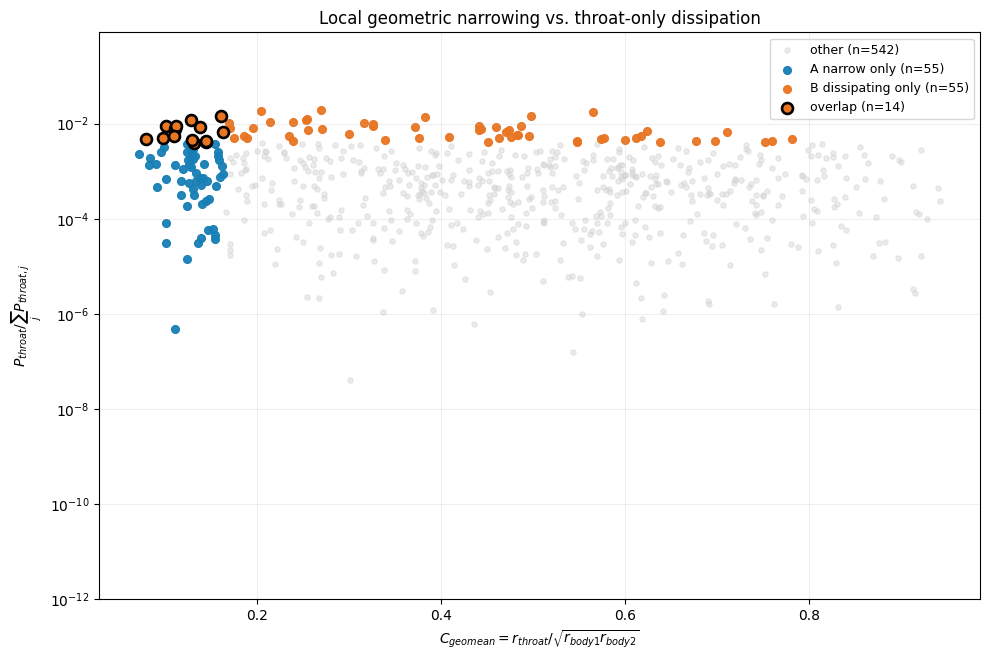

In [42]:
def plot_constriction_vs_dissipation(selected):
    """Reproduce the geometric constriction–throat dissipation scatter plot."""
    fig, ax = plt.subplots(figsize=(10, 6.7))
    styles = [
        ('other', '#d3d3d3', 14, 0.45),
        ('A_narrow_only', '#177fb5', 31, 0.95),
        ('B_dissipating_only', '#e87522', 31, 0.95),
        ('C_overlap', '#e87522', 62, 1.0),
    ]
    nonzero = selected.loc[(selected['P_throat_fraction'] > 0) & selected['eligible']]
    for name, color, size, alpha in styles:
        d = nonzero[nonzero.group == name]
        if d.empty:
            continue
        if name == 'C_overlap':
            ax.scatter(d.C_geomean, d.P_throat_fraction, facecolor=color,
                       edgecolor='black', linewidth=1.9, s=size,
                       alpha=alpha, label=f'overlap (n={len(d)})', zorder=5)
        else:
            ax.scatter(d.C_geomean, d.P_throat_fraction, s=size, c=color,
                       alpha=alpha, label=f'{name.replace("_", " ")} (n={len(d)})')
    ax.set_yscale('log')
    ax.set_xlabel(r'$C_{geomean} = r_{throat}/\sqrt{r_{body1}r_{body2}}$')
    ax.set_ylabel(r'$P_{throat}/\sum_j P_{throat,j}$')
    ax.set_title('Local geometric narrowing vs. throat-only dissipation')
    ax.grid(True, alpha=0.20)
    ax.legend(loc='best', fontsize=9)
    ax.set_ylim(bottom=1e-12)
    fig.tight_layout()
    plt.show()
    return fig

scatter_figure = plot_constriction_vs_dissipation(selected)

In [43]:
def report_selected_throats(selected, max_rows=30):
    """Inspect the overlap throats first, followed by other selected throats."""
    cols = ['group', 'throat_id', 'body1_id', 'body2_id', 'C_geomean',
            'P_throat_fraction', 'P_network_fraction', 'current',
            'r_throat_geom', 'coordination_body1', 'coordination_body2',
            'is_fallback', 'center_0', 'center_1', 'center_2']
    ranked = selected.copy()
    ranked['_priority'] = ranked.group.map({'C_overlap': 0, 'B_dissipating_only': 1,
                                            'A_narrow_only': 2, 'other': 3})
    ranked = ranked.sort_values(['_priority', 'P_throat_fraction'],
                                ascending=[True, False])
    display(ranked[cols].head(max_rows).round(6))
    print('Overlap throat IDs:', selected.loc[selected.group == 'C_overlap',
                                             'throat_id'].tolist())
    return ranked.drop(columns='_priority')

candidate_table = report_selected_throats(selected, max_rows=20)

,group,throat_id,body1_id,body2_id,C_geomean,P_throat_fraction,P_network_fraction,current,r_throat_geom,coordination_body1,coordination_body2,is_fallback,center_0,center_1,center_2
37,C_overlap,38,26,73,0.160472,0.014282,0.006125,0.320963,1.000000,2,3,False,21.000000,0.888889,4.444444
226,C_overlap,227,106,169,0.128037,0.011950,0.005124,0.369293,1.414214,10,6,False,72.714286,96.714286,53.785714
106,C_overlap,107,56,104,0.100501,0.009058,0.003884,0.338120,1.000000,9,5,False,40.571429,36.142857,144.142857
287,C_overlap,288,135,178,0.111517,0.008703,0.003732,0.375054,1.000000,6,8,False,75.900000,92.400000,125.000000
436,C_overlap,437,185,286,0.137302,0.008646,0.003707,0.348085,2.000000,17,14,False,103.044118,29.705882,16.323529
107,C_overlap,108,56,105,0.110807,0.007694,0.003299,0.400825,1.414214,9,11,False,38.666667,49.745098,120.823529
79,C_overlap,80,46,84,0.162835,0.006803,0.002917,0.453822,2.449490,8,10,False,29.017094,91.111111,39.418803
559,C_overlap,560,228,290,0.109920,0.005547,0.002379,0.180988,1.000000,11,3,False,121.500000,108.500000,82.500000
256,C_overlap,257,120,193,0.097517,0.004923,0.002111,0.182534,1.000000,7,8,False,74.500000,149.000000,118.500000
470,C_overlap,471,196,286,0.079426,0.004860,0.002084,0.242172,1.000000,7,14,False,103.692308,44.115385,43.461538


Overlap throat IDs: [38, 80, 107, 108, 123, 227, 257, 267, 288, 362, 378, 437, 471, 560]


# Phase 3 — Localize candidates in napari

The network reconstruction provides each `PoreThroat.coords` array (the original throat voxel coordinates) and `PoreThroat.center`. The overlay shows three distinct candidate groups, the corresponding body labels, and optional centroid-to-centroid network connections. Graph lines are **schematic**: the throat voxel labels show the actual extracted neck locations.

**GUI note:** napari needs a local desktop/Qt-capable Jupyter kernel. If necessary, install `napari[all]` in that environment. For very large volumes, disable expensive layers in the viewer or use the points layer alone.

In [9]:
def make_napari_overlays(geometry, selected):
    """Create throat-ID volumes and point feature tables in original voxel axes."""
    shape = geometry['merged_bodies'].shape
    net = geometry['network']
    names = ('A_narrow_only', 'B_dissipating_only', 'C_overlap')
    masks = {name: np.zeros(shape, dtype=np.int32) for name in names}
    points = {}
    for name in names:
        subset = selected[selected.group == name].copy()
        for tid in subset.throat_id.astype(int):
            coords = np.asarray(net.throats[tid].coords, dtype=int)
            masks[name][tuple(coords.T)] = tid  # keep original throat ID for click inspection
        points[name] = subset

    # In some segmented networks throat-coordinate sets overlap each other;
    # the original throat_array and each group label volume use last-write-wins.
    # Throat center point features remain independent and preserve every throat.
    candidate = selected[selected.group != 'other']
    overlap_bodies = set(candidate.loc[candidate.group == 'C_overlap', 'body1_id'])
    overlap_bodies.update(candidate.loc[candidate.group == 'C_overlap', 'body2_id'])
    b = geometry['merged_bodies']
    body_overlay = np.where(np.isin(b, list(overlap_bodies)), b, 0).astype(np.int32)
    overlays = dict(group_labels=masks, points=points,
                    selected_body_labels=body_overlay,
                    all_throat_labels=net.throat_array)
    print('Prepared group labels and throat points in array-index order (axis 0, 1, 2).')
    return overlays

overlays = make_napari_overlays(geometry, selected)

Prepared group labels and throat points in array-index order (axis 0, 1, 2).


In [94]:
def launch_transport_napari(geometry, selected, overlays, include_network_lines=True):
    """Open a 3D viewer with phase morphology, candidate throats and body IDs."""
    if napari is None:
        raise ImportError('napari is not installed in this notebook environment. Install napari[all].')
    # Qt loop integration for a local IPython/Jupyter desktop kernel.
    try:
        from IPython import get_ipython
        ip = get_ipython()
        if ip is not None:
            ip.run_line_magic('gui', 'qt')
    except Exception as exc:
        print('Qt event loop could not be enabled automatically:', exc)

    viewer = napari.Viewer(ndisplay=3, title='Berg RN — local transport bottlenecks')
    phase = (geometry['merged_bodies'] > 0).astype(np.uint8)
    viewer.add_image(phase, name='Conducting phase', colormap='gray',
                     opacity=0.18, rendering='iso', visible=True)
    viewer.add_labels(geometry['merged_bodies'], name='Merged body IDs', visible=False)
    viewer.add_labels(overlays['selected_body_labels'],
                      name='Bodies beside overlap throats', opacity=0.35, visible=True)
    viewer.add_labels(overlays['all_throat_labels'], name='All throat IDs', visible=False)

    colors = {'A_narrow_only': '#177fb5',
              'B_dissipating_only': '#e87522', 'C_overlap': '#cf293d'}
    for name, color in colors.items():
        volume = overlays['group_labels'][name]
        viewer.add_labels(volume, name=f'Throat voxels — {name}', visible=False)
        frame = overlays['points'][name]
        if len(frame):
            coords = frame[['center_0', 'center_1', 'center_2']].to_numpy(float)
            viewer.add_points(coords, name=f'Throat centers — {name}',
                              ndim=3, size=4.5, face_color=color,
                             features=frame.reset_index(drop=True),
                              visible=True)

    if include_network_lines:
        arr = np.asarray(geometry['network'].body_centroids, dtype=float)
        # Body centroids are in the same order as sorted body IDs.
        body_ids = sorted(geometry['network'].bodies)
        lookup = {int(bid): i for i, bid in enumerate(body_ids)}
        active = selected[selected.group != 'other']
        segments = np.stack([
            np.stack((arr[lookup[int(row.body1_id)]], arr[lookup[int(row.body2_id)]]), axis=0)
            for row in active.itertuples()
        ], axis=0) if len(active) else np.empty((0, 2, 3))
        if len(segments):
            viewer.add_shapes(segments, name='Selected RN links (schematic)',
                              shape_type='line',
                              edge_width=1.5, face_color='transparent',
                              visible=False)


    # ==================================================
    # 8. Box geometry
    # ==================================================

    extent = np.asarray(geometry['merged_bodies'].shape, dtype=float) - 1

    corners = np.array([
        [0, 0, 0],
        [extent[0], 0, 0],
        [0, extent[1], 0],
        [0, 0, extent[2]],
        [extent[0], extent[1], 0],
        [extent[0], 0, extent[2]],
        [0, extent[1], extent[2]],
        [extent[0], extent[1], extent[2]],
    ])

    edge_pairs = [
        (0, 1), (0, 2), (0, 3),
        (1, 4), (1, 5),
        (2, 4), (2, 6),
        (3, 5), (3, 6),
        (4, 7), (5, 7), (6, 7),
    ]

    box_lines = [
        np.stack([corners[i], corners[j]])
        for i, j in edge_pairs
    ]

    viewer.add_shapes(box_lines, name='Volume bounding box', shape_type='line',
                        edge_width=1.0, face_color='transparent', visible=True)

    viewer.dims.ndisplay = 3
    print('Click throat-center points to inspect the feature table, or enable the '
          'throat-ID label layers and use napari label picking.')
    return viewer

# Requires a desktop-capable Qt environment; comment out this invocation when running headless.
viewer = launch_transport_napari(geometry, selected, overlays) if napari is not None else None
if viewer is None:
    print('napari not installed: the spatial overlays are ready but no GUI was launched.')

RuntimeError: sequence argument must have length equal to input rank

RuntimeError: sequence argument must have length equal to input rank

RuntimeError: sequence argument must have length equal to input rank

RuntimeError: sequence argument must have length equal to input rank

RuntimeError: sequence argument must have length equal to input rank

Click throat-center points to inspect the feature table, or enable the throat-ID label layers and use napari label picking.


# Phase 4 — Group candidate throats into candidate transport-limiting regions

Here, a **region** initially means a connected component in the *subgraph formed by selected overlap throats* (two selected throats are joined if they share a body). We also compute an alternative **spatial-neighbor grouping** using throat-center distance. These groupings are exploratory: sharing a network body and being physically close are different criteria.

Start with the overlap group, then optionally repeat on all three candidate populations. A region is a *candidate*, not yet a proven macroscopic transport bottleneck; that requires the perturbation tests in Phase 5 (not included in this notebook).

In [44]:
def connected_throat_regions(selected, group='C_overlap'):
    """Identify connected sets of selected throats through shared body IDs."""
    df = selected.copy()
    pick = df.loc[df.group == group]
    graph = nx.Graph()
    graph.add_nodes_from(pick.throat_id.astype(int))
    body_to_throats = {}
    for row in pick.itertuples():
        for body in (int(row.body1_id), int(row.body2_id)):
            body_to_throats.setdefault(body, []).append(int(row.throat_id))
    for tids in body_to_throats.values():
        if len(tids) > 1:
            nx.add_path(graph, tids)
    comps = sorted(nx.connected_components(graph), key=lambda c: (-len(c), min(c)))
    region_map = {tid: i + 1 for i, comp in enumerate(comps) for tid in comp}
    df['graph_region'] = df.throat_id.map(region_map).fillna(0).astype(int)
    rows = []
    for i, ids in enumerate(comps, start=1):
        members = df.loc[df.throat_id.isin(ids)]
        points = members[['center_0', 'center_1', 'center_2']].to_numpy(float)
        bodies = sorted(set(members.body1_id.astype(int)) | set(members.body2_id.astype(int)))
        rows.append(dict(region_id=i, n_throats=len(ids), throat_ids=sorted(ids),
                         body_ids=bodies, sum_P_throat_fraction=float(members.P_throat_fraction.sum()),
                         min_C_geomean=float(members.C_geomean.min()),
                         center_0=float(points[:, 0].mean()),
                         center_1=float(points[:, 1].mean()),
                         center_2=float(points[:, 2].mean()),
                         bbox_min=tuple(points.min(axis=0)), bbox_max=tuple(points.max(axis=0))))
    regions = pd.DataFrame(rows)
    print(f'{len(pick)} throats from {group} -> {len(regions)} body-connected regions.')
    if len(regions):
        display(regions[['region_id', 'n_throats', 'throat_ids', 'body_ids',
                         'sum_P_throat_fraction', 'min_C_geomean']])
    return df, regions

selected_regions, graph_regions = connected_throat_regions(selected, group='C_overlap')

14 throats from C_overlap -> 11 body-connected regions.


,region_id,n_throats,throat_ids,body_ids,sum_P_throat_fraction,min_C_geomean
0,1,2,"[107, 108]","[56, 104, 105]",0.016752,0.100501
1,2,2,"[227, 362]","[106, 169, 214]",0.016506,0.128037
2,3,2,"[437, 471]","[185, 196, 286]",0.013506,0.079426
3,4,1,[38],"[26, 73]",0.014282,0.160472
4,5,1,[80],"[46, 84]",0.006803,0.162835
5,6,1,[123],"[64, 100]",0.004085,0.144764
6,7,1,[257],"[120, 193]",0.004923,0.097517
7,8,1,[267],"[125, 175]",0.003922,0.130766
8,9,1,[288],"[135, 178]",0.008703,0.111517
9,10,1,[378],"[173, 240]",0.004374,0.144479


In [45]:
def distance_based_throat_regions(selected_regions, group='C_overlap',
                                  radius_voxels=12.0):
    """Alternative clustering using distances between selected throat centers."""
    df = selected_regions.copy()
    pick = df.loc[df.group == group]
    if radius_voxels <= 0:
        raise ValueError('radius_voxels must be positive.')
    g = nx.Graph()
    tids = pick.throat_id.to_numpy(dtype=int)
    xyz = pick[['center_0', 'center_1', 'center_2']].to_numpy(dtype=float)
    g.add_nodes_from(tids)
    if len(xyz) >= 2:
        neighbors = cKDTree(xyz).query_pairs(r=radius_voxels)
        g.add_edges_from((int(tids[i]), int(tids[j])) for i, j in neighbors)
    comps = sorted(nx.connected_components(g), key=lambda c: (-len(c), min(c)))
    region_map = {tid: i + 1 for i, c in enumerate(comps) for tid in c}
    df['distance_region'] = df.throat_id.map(region_map).fillna(0).astype(int)
    comparison = df.loc[df.group == group, [
        'throat_id', 'body1_id', 'body2_id', 'graph_region', 'distance_region',
        'C_geomean', 'P_throat_fraction'
    ]].sort_values(['graph_region', 'distance_region', 'throat_id'])
    print(f'Body-connected groups: {pick.graph_region.nunique()} | '
          f'center-distance groups (radius {radius_voxels:g} vox): {len(comps)}')
    display(comparison)
    return df

# Example: centroid distances up to 12 voxel units (adjust to suit the structure).
selected_regions = distance_based_throat_regions(
    selected_regions, group='C_overlap', radius_voxels=12.0
)

Body-connected groups: 11 | center-distance groups (radius 12 vox): 14


,throat_id,body1_id,body2_id,graph_region,distance_region,C_geomean,P_throat_fraction
106,107,56,104,1,3,0.100501,0.009058
107,108,56,105,1,4,0.110807,0.007694
226,227,106,169,2,6,0.128037,0.011950
361,362,169,214,2,10,0.129108,0.004556
436,437,185,286,3,12,0.137302,0.008646
470,471,196,286,3,13,0.079426,0.004860
37,38,26,73,4,1,0.160472,0.014282
79,80,46,84,5,2,0.162835,0.006803
122,123,64,100,6,5,0.144764,0.004085
256,257,120,193,7,7,0.097517,0.004923


In [49]:
def overlay_regions_in_napari(viewer, geometry, selected_regions, group='C_overlap'):
    """Add one labeled 3D region layer and one centroid-point layer to napari."""
    if viewer is None:
        print('No napari viewer supplied; skipping GUI overlay.')
        return None
    picked = selected_regions[(selected_regions.group == group) &
                              (selected_regions.graph_region > 0)]
    shape = geometry['merged_bodies'].shape
    region_labels = np.zeros(shape, np.int32)
    for row in picked.itertuples():
        coords = np.asarray(geometry['network'].throats[int(row.throat_id)].coords, int)
        region_labels[tuple(coords.T)] = int(row.graph_region)
    viewer.add_labels(region_labels, name='Overlap regions (shared-body)',
                      opacity=0.85, visible=True)
    if len(picked):
        groups = []
        for rid, members in picked.groupby('graph_region'):
            groups.append({
                'region_id': int(rid), 'n_throats': len(members),
                'center_0': float(members.center_0.mean()),
                'center_1': float(members.center_1.mean()),
                'center_2': float(members.center_2.mean()),
                'throat_ids': ','.join(map(str, sorted(members.throat_id.tolist()))),
            })
        feat = pd.DataFrame(groups)
        viewer.add_points(feat[['center_0', 'center_1', 'center_2']].to_numpy(),
                          name='Candidate region centers', ndim=3, size=8,
                          face_color='#f9ed69',
                          features=feat, visible=True)
    print('Region labels and centers added to napari. Inspect body connections '
          'and compare nearby regions interactively.')
    return region_labels

region_volume = overlay_regions_in_napari(viewer, geometry, selected_regions)

Region labels and centers added to napari. Inspect body connections and compare nearby regions interactively.


## Notebook outcome and next steps

You now have (1) an ID-validated reconstructed network, (2) a table of each throat's geometric ratio and saved-network dissipation, (3) selected narrow-only / dissipating-only / overlap populations, (4) napari overlays at the actual extracted throat voxels, and (5) optional connected-region labels.

**Interpretation notes:** geometric area and solver/fallback area are intentionally distinct. `P_throat_fraction` is normalized over throat segments only; it is **not** a fraction of the entire network's power. A graph-connected region can span many physical voxels, while spatial clustering may put together throats with no direct network adjacency. Neither proves that a geometric intervention will improve the effective conductivity; that would be the next phase.

## Compare vector fields

In [87]:
def visualize_transport_heatmaps(
    run,
    geometry,
    percentile=99,
    opacity=0.8,
    gamma=0.8,
    rendering="translucent",
    chunk_size=100_000,
):
    """
    Visualize full-domain 3D transport magnitudes.

    Berg RN:
      - Body voxels: |I| / A_body for the nearest
        body-centroid-to-throat segment.
      - Throat voxels: |I| / A_throat.
      - Uses the actual solved edge currents and effective
        areas of the Berg three-resistor model.

    TauFactor:
      - Actual saved cell-centered flux magnitude.

    Creates two independent napari viewers with:
      - Black-to-white heatmaps
      - Transparent solid phase
      - Independent percentile normalization
      - 3D domain bounding box
      - XYZ axes outside the bounding box

    Returns
    -------
    viewer_rn, viewer_tau, fields
    """

    import numpy as np
    import napari
    from scipy import ndimage as ndi
    from napari.utils.colormaps import Colormap

    # ==================================================
    # 1. Load existing data
    # ==================================================

    a = run["saved"]["arrays"]
    net = geometry["network"]

    labels = np.asarray(geometry["merged_bodies"])
    pore_rn = labels > 0
    shape = labels.shape

    currents = np.asarray(
        run["saved"]["current"], dtype=float
    )
    conns = np.asarray(a["conns"], dtype=int)
    body_ids = np.asarray(a["body_ids"], dtype=int)
    throat_ids = np.asarray(a["throat_ids"], dtype=int)
    body_centers = np.asarray(a["coords"], dtype=float)

    A1 = np.asarray(a["A_body1"], dtype=float)
    At = np.asarray(a["throat_area"], dtype=float)
    A2 = np.asarray(a["A_body2"], dtype=float)

    if len(currents) != len(throat_ids):
        raise ValueError("RN currents and throat IDs are misaligned.")


    import pickle
    import cache_utils

    tau_dir = cache_utils.resolve_real_dir(
        run["folder"],
        run["version"],
        "taufactor"
    )

    tau_path = tau_dir / "full_result.pkl"

    with open(tau_path, "rb") as f:
        tau_result = pickle.load(f)

    print(f"Loaded TauFactor fields from: {tau_path}")

    # ==================================================
    # 2. Actual TauFactor flux magnitude
    # ==================================================

    Jx = np.asarray(tau_result["J_x"], dtype=np.float32)
    Jy = np.asarray(tau_result["J_y"], dtype=np.float32)
    Jz = np.asarray(tau_result["J_z"], dtype=np.float32)

    if any(J.shape != shape for J in (Jx, Jy, Jz)):
        raise ValueError("TauFactor field shape mismatch.")

    pore_tau = np.asarray(
        tau_result.get("pore_mask", pore_rn), dtype=bool
    )

    if pore_tau.shape != shape:
        raise ValueError("TauFactor pore mask shape mismatch.")

    if not np.array_equal(pore_rn, pore_tau):
        print(
            "WARNING: RN and TauFactor conducting masks differ "
            f"at {np.count_nonzero(pore_rn != pore_tau):,} voxels."
        )

    tau_mag = np.sqrt(
        Jx.astype(np.float64)**2
        + Jy.astype(np.float64)**2
        + Jz.astype(np.float64)**2
    ).astype(np.float32)

    tau_mag[~pore_tau] = np.nan

    # ==================================================
    # 3. Prepare RN body-segment properties
    # ==================================================

    # Each RN connection has two body segments.
    # Associate both with the appropriate body ID.

    incident = [[] for _ in body_ids]

    for k, (i, j) in enumerate(conns):

        if i < 0 or j < 0:
            continue

        if not np.isfinite(currents[k]):
            continue

        throat = net.throats.get(int(throat_ids[k]))

        if throat is None or throat.center is None:
            continue

        center = np.asarray(throat.center, dtype=float)

        if not np.all(np.isfinite(center)):
            continue

        if np.isfinite(A1[k]) and A1[k] > 0:
            incident[i].append(
                (center, abs(currents[k]) / A1[k])
            )

        if np.isfinite(A2[k]) and A2[k] > 0:
            incident[j].append(
                (center, abs(currents[k]) / A2[k])
            )

    # ==================================================
    # 4. Reconstruct flux magnitude inside all bodies
    # ==================================================

    # The RN solves segment-average current densities,
    # not individual voxel fluxes.
    #
    # For each body voxel, find the closest incident
    # body-center -> throat-center segment.
    #
    # Assign its |I| / A_body magnitude.
    #
    # This is a spatial projection of the RN solution,
    # not an additional transport calculation.

    rn_mag = np.full(shape, np.nan, dtype=np.float32)

    body_slices = ndi.find_objects(labels)

    for body_idx, bid in enumerate(body_ids):

        bid = int(bid)

        if bid <= 0 or bid > len(body_slices):
            continue

        slc = body_slices[bid - 1]

        if slc is None:
            continue

        local = np.argwhere(labels[slc] == bid)

        if len(local) == 0:
            continue

        origin = np.array(
            [s.start for s in slc], dtype=int
        )

        connections = incident[body_idx]

        # Bodies without a solved active connection
        # are assigned zero flux.
        if not connections:
            xyz = local + origin
            rn_mag[tuple(xyz.T)] = 0.0
            continue

        body_center = body_centers[body_idx]

        for start in range(0, len(local), chunk_size):

            xyz = (
                local[start:start + chunk_size] + origin
            )

            points = xyz.astype(np.float64)

            relative = points - body_center

            best_distance = np.full(
                len(points), np.inf, dtype=float
            )
            best_magnitude = np.zeros(
                len(points), dtype=np.float32
            )

            for throat_center, J_segment in connections:

                # Segment from body centroid to throat center
                vector = throat_center - body_center

                length_sq = float(np.dot(vector, vector))

                if length_sq <= 1e-20:
                    dist_sq = np.sum(
                        relative**2, axis=1
                    )
                else:
                    # Project voxel onto the finite segment
                    t = np.clip(
                        (relative @ vector) / length_sq,
                        0.0,
                        1.0
                    )

                    closest_relative = t[:, None] * vector

                    dist_sq = np.sum(
                        (relative - closest_relative)**2,
                        axis=1
                    )

                update = dist_sq < best_distance

                best_distance[update] = dist_sq[update]
                best_magnitude[update] = J_segment

            rn_mag[tuple(xyz.T)] = best_magnitude

    # ==================================================
    # 5. Overlay actual RN throat-segment magnitudes
    # ==================================================

    # Throat voxels get |I| / A_throat.
    # Where reconstructed throat voxel sets overlap,
    # retain the largest segment magnitude.

    for k, tid in enumerate(throat_ids):

        if (
            At[k] <= 0
            or not np.isfinite(At[k])
            or not np.isfinite(currents[k])
        ):
            continue

        throat = net.throats.get(int(tid))

        if throat is None or throat.coords is None:
            continue

        coords = np.asarray(throat.coords, dtype=int)

        if coords.size == 0:
            continue

        valid = np.all(
            (coords >= 0)
            & (coords < np.asarray(shape)),
            axis=1
        )

        coords = coords[valid]

        if len(coords) == 0:
            continue

        coords = coords[pore_rn[tuple(coords.T)]]

        if len(coords) == 0:
            continue

        magnitude = abs(currents[k]) / At[k]

        idx = tuple(coords.T)

        rn_mag[idx] = np.fmax(
            rn_mag[idx], magnitude
        )

    rn_mag[~pore_rn] = np.nan

    # ==================================================
    # 6. Normalize both heatmaps independently
    # ==================================================

    # Reserve exactly zero for transparent solid.
    # Pore voxels, including zero-current ones, get
    # a small positive display value.

    displays = []
    scales = []

    for field in (rn_mag, tau_mag):

        finite = np.isfinite(field)
        positive = field[finite & (field > 0)]

        if positive.size == 0:
            raise ValueError(
                "A transport field contains no positive values."
            )

        scale = float(
            np.percentile(positive, percentile)
        )

        norm = np.zeros(shape, dtype=np.float32)

        values = np.clip(
            field[finite] / max(scale, 1e-30),
            0.0, 1.0
        )

        values = values ** gamma

        # Separate transparent solid from black zero-flux pore
        norm[finite] = 0.005 + 0.995 * values

        displays.append(norm)
        scales.append(scale)

    rn_display, tau_display = displays
    rn_scale, tau_scale = scales

    # ==================================================
    # 7. Grayscale colormap with transparency
    # ==================================================

    # 0.0 = transparent solid
    # 0.005 = black, low/zero flux
    # 1.0 = white, highest flux

    cmap = Colormap(
        colors=np.array([
            [0.00, 0.00, 0.00, 0.00],
            [0.00, 0.00, 0.00, 0.30],
            [0.25, 0.25, 0.25, 0.50],
            [0.65, 0.65, 0.65, 0.80],
            [1.00, 1.00, 1.00, 1.00],
        ]),
        controls=np.array([
            0.0, 0.005, 0.25, 0.65, 1.0
        ]),
        name="transparent_grayscale",
    )

    # ==================================================
    # 8. Box geometry
    # ==================================================

    extent = np.asarray(shape, dtype=float) - 1

    corners = np.array([
        [0, 0, 0],
        [extent[0], 0, 0],
        [0, extent[1], 0],
        [0, 0, extent[2]],
        [extent[0], extent[1], 0],
        [extent[0], 0, extent[2]],
        [0, extent[1], extent[2]],
        [extent[0], extent[1], extent[2]],
    ])

    edge_pairs = [
        (0, 1), (0, 2), (0, 3),
        (1, 4), (1, 5),
        (2, 4), (2, 6),
        (3, 5), (3, 6),
        (4, 7), (5, 7), (6, 7),
    ]

    box_lines = [
        np.stack([corners[i], corners[j]])
        for i, j in edge_pairs
    ]

    # ==================================================
    # 9. Separate XYZ axes outside the bounding box
    # ==================================================

    dimension = float(max(shape))

    axis_origin = np.array(
        [-0.16, -0.16, -0.16]
    ) * dimension

    axis_length = 0.12 * dimension

    axis_lines = []

    for axis in range(3):
        endpoint = axis_origin.copy()
        endpoint[axis] += axis_length

        axis_lines.append(
            np.stack([axis_origin, endpoint])
        )

    # ==================================================
    # 10. Create two independent 3D viewers
    # ==================================================

    viewers = []

    for name, image in [
        ("Berg RN — 3D Current Density", rn_display),
        ("TauFactor — 3D Flux Magnitude", tau_display),
    ]:

        viewer = napari.Viewer(
            ndisplay=3,
            title=name,
        )

        viewer.add_image(
            image,
            name=name,
            colormap=cmap,
            contrast_limits=(0, 1),
            rendering=rendering,
            opacity=opacity,
            depiction="volume",
        )

        viewer.add_shapes(
            box_lines,
            shape_type="line",
            edge_color="white",
            edge_width=1.0,
            name="Bounding box",
        )

        viewer.add_shapes(
            axis_lines,
            shape_type="line",
            edge_color=["red", "lime", "dodgerblue"],
            edge_width=3,
            name="External XYZ axes",
        )

        # XYZ label markers
        endpoints = np.array(
            [line[1] for line in axis_lines]
        )

        viewer.add_points(
            endpoints,
            name="XYZ labels",
            size=0.1,
            face_color="transparent",
            features={
                "axis": ["X", "Y", "Z"]
            },
            text={
                "string": "{axis}",
                "color": "white",
                "size": 14,
            },
        )

        # Napari's orientation axes in the viewer corner
        viewer.axes.visible = True
        viewer.axes.labels = True

        viewer.dims.ndisplay = 3
        viewers.append(viewer)

    # ==================================================
    # 11. Report and return fields
    # ==================================================

    print("\n3D TRANSPORT HEATMAPS")
    print("-" * 50)
    print(f"Volume: {shape}")
    print(f"RN mapped pore voxels: {np.isfinite(rn_mag).sum():,}")
    print(f"TauFactor mapped voxels: {np.isfinite(tau_mag).sum():,}")
    print(f"RN {percentile}th-percentile scale: {rn_scale:.6g}")
    print(f"TauFactor {percentile}th-percentile scale: {tau_scale:.6g}")

    fields = {
        "rn_magnitude": rn_mag,
        "tau_magnitude": tau_mag,
        "rn_normalized": rn_display,
        "tau_normalized": tau_display,
        "rn_scale": rn_scale,
        "tau_scale": tau_scale,
    }

    return viewers[0], viewers[1], fields

In [89]:
# Pass the valid saved TauFactor dictionary you already loaded.
viewer_rn, viewer_tau, transport_fields = visualize_transport_heatmaps(
    run,
    geometry,
    percentile=99.99,
    opacity=0.8,
    gamma=0.8,
    rendering="mip",
)

Loaded TauFactor fields from: /Users/rochan/Downloads/Rochan/Research/Claude_Code/Constrictivity/TRACE_fine_test/Fine_microstructure_0/version1/taufactor/full_result.pkl

3D TRANSPORT HEATMAPS
--------------------------------------------------
Volume: (150, 150, 150)
RN mapped pore voxels: 1,574,004
TauFactor mapped voxels: 1,574,004
RN 99.99th-percentile scale: 0.0220632
TauFactor 99.99th-percentile scale: 0.0361734


## Phase 5: What makes these bottleneck regions special?

In [46]:
def phase5_build_body_table(run, geometry, selected):
    """Return body-level morphology, topology, boundary and location data."""
    import numpy as np
    import pandas as pd
    import networkx as nx

    a = run["saved"]["arrays"]
    bids = np.asarray(a["body_ids"], int)
    conns = np.asarray(a["conns"], int)
    I = np.asarray(run["saved"]["current"], float)

    labels = np.asarray(geometry["merged_bodies"])
    shape = np.asarray(labels.shape)
    axis = geometry["axis"]

    groups = (
        "C_overlap",
        "A_narrow_only",
        "B_dissipating_only",
    )

    # Graph built from the actual saved RN connectivity
    G = nx.Graph()
    G.add_nodes_from(bids.tolist())

    throat_counts = dict.fromkeys(bids.tolist(), 0)
    active_counts = dict.fromkeys(bids.tolist(), 0)

    threshold = (
        float(np.nanmax(np.abs(I))) * 1e-10
        if I.size else 0.0
    )

    for k, (i, j) in enumerate(conns):
        if i < 0 or j < 0:
            continue

        u, v = int(bids[i]), int(bids[j])
        G.add_edge(u, v)

        throat_counts[u] += 1
        throat_counts[v] += 1

        if abs(I[k]) > threshold:
            active_counts[u] += 1
            active_counts[v] += 1

    # The exact boundary classification used by Berg RN
    inlet_idx, outlet_idx = berg_cc.get_inlet_outlet_indices(
        a,
        labels,
        direction=run["config"].get("direction", "x"),
    )

    inlet_ids = set(bids[inlet_idx])
    outlet_ids = set(bids[outlet_idx])

    # Separately track actual geometric face contact
    inlet_face_ids = set(
        np.unique(np.take(labels, 0, axis=axis))
    ) - {0}

    outlet_face_ids = set(
        np.unique(np.take(labels, -1, axis=axis))
    ) - {0}

    # Actual body-label volume versus RN model volume
    counts = np.bincount(labels.ravel().astype(np.int64))

    label_vols = np.array([
        counts[b] if b < len(counts) else 0
        for b in bids
    ])

    centroids = np.asarray(a["coords"], float)
    normalized = centroids / np.maximum(shape - 1, 1)

    # Removing an articulation body disconnects its
    # connected component in the undirected graph.
    articulation = set(nx.articulation_points(G))

    df = pd.DataFrame({
        "body_id": bids,

        "volume_voxels": label_vols.astype(float),
        "volume_RN": np.asarray(a["volumes"], float),

        "coordination": [
            G.degree[int(b)] for b in bids
        ],
        "n_throats": [
            throat_counts[int(b)] for b in bids
        ],
        "n_active_throats": [
            active_counts[int(b)] for b in bids
        ],

        "is_articulation": [
            b in articulation for b in bids
        ],

        "is_surface": np.asarray(a["is_surface"], bool),
        "is_inlet": [b in inlet_ids for b in bids],
        "is_outlet": [b in outlet_ids for b in bids],

        "touches_inlet_face": [
            b in inlet_face_ids for b in bids
        ],
        "touches_outlet_face": [
            b in outlet_face_ids for b in bids
        ],

        **{
            f"center_{k}": centroids[:, k]
            for k in range(3)
        },
        **{
            f"position_{k}": normalized[:, k]
            for k in range(3)
        },

        "flow_position": normalized[:, axis],

        "distance_to_flow_face": np.minimum(
            normalized[:, axis],
            1 - normalized[:, axis],
        ),

        "distance_to_any_face": np.minimum(
            normalized, 1 - normalized
        ).min(axis=1),
    }).set_index("body_id", drop=False)

    # One body can touch multiple candidate populations
    for group in groups:
        edges = selected.loc[
            selected["group"].eq(group),
            ["body1_id", "body2_id"],
        ]

        ids = set(
            edges.to_numpy().astype(int).ravel()
        )

        df[f"in_{group}"] = df["body_id"].isin(ids)

    df["candidate_groups"] = sum(
        df[f"in_{g}"].astype(int) for g in groups
    )

    # Exclusive classification for visualization only
    df["body_role"] = np.select(
        [
            df.in_C_overlap,
            df.in_A_narrow_only & df.in_B_dissipating_only,
            df.in_A_narrow_only,
            df.in_B_dissipating_only,
        ],
        [
            "C_overlap",
            "A_and_B",
            "A_narrow_only",
            "B_dissipating_only",
        ],
        default="other",
    )

    df["boundary_status"] = np.select(
        [
            df.is_inlet & df.is_outlet,
            df.is_inlet,
            df.is_outlet,
        ],
        ["both", "inlet", "outlet"],
        default="interior",
    )

    df["volume_percentile"] = (
        df.volume_voxels.rank(pct=True) * 100
    )
    df["coordination_percentile"] = (
        df.coordination.rank(pct=True) * 100
    )

    print(f"Total bodies: {len(df)}")
    print(f"RN inlet bodies: {df.is_inlet.sum()}")
    print(f"RN outlet bodies: {df.is_outlet.sum()}")
    print("\nBody classifications:")
    print(df.body_role.value_counts().to_string())

    return df, G


body_df, body_graph = phase5_build_body_table(
    run, geometry, selected
)

Total bodies: 310
RN inlet bodies: 27
RN outlet bodies: 29

Body classifications:
body_role
other                 175
A_narrow_only          53
B_dissipating_only     41
C_overlap              25
A_and_B                16


In [47]:
def phase5_compare_body_groups(body_df):
    """Compare direct candidate bodies against noncandidate controls."""
    import pandas as pd

    groups = (
        "C_overlap",
        "A_narrow_only",
        "B_dissipating_only",
    )

    baseline = body_df.loc[
        body_df.candidate_groups == 0
    ]

    rows = []

    for group in groups:
        primary = body_df.loc[
            body_df[f"in_{group}"]
        ]

        for tier, d in [
            ("direct", primary),
            ("unselected_control", baseline),
        ]:
            if d.empty:
                continue

            rows.append({
                "group": group,
                "tier": tier,
                "n_bodies": len(d),

                "median_volume": d.volume_voxels.median(),
                "median_volume_RN": d.volume_RN.median(),
                "median_coordination": d.coordination.median(),

                "median_volume_percentile":
                    d.volume_percentile.median(),

                "median_coordination_percentile":
                    d.coordination_percentile.median(),

                "fraction_degree_le2":
                    (d.coordination <= 2).mean(),

                "fraction_articulation":
                    d.is_articulation.mean(),

                "n_inlet": int(d.is_inlet.sum()),
                "n_outlet": int(d.is_outlet.sum()),

                "fraction_face_contact": (
                    d.touches_inlet_face
                    | d.touches_outlet_face
                ).mean(),

                "median_flow_position":
                    d.flow_position.median(),

                "median_distance_any_face":
                    d.distance_to_any_face.median(),
            })

    summary = pd.DataFrame(rows)

    display(summary.round(3))

    return summary


body_comparison = phase5_compare_body_groups(body_df)

,group,tier,n_bodies,median_volume,median_volume_RN,median_coordination,median_volume_percentile,median_coordination_percentile,fraction_degree_le2,fraction_articulation,n_inlet,n_outlet,fraction_face_contact,median_flow_position,median_distance_any_face
0,C_overlap,direct,25,7359.0,7359.0,7.0,79.355,83.871,0.080,0.120,2,2,0.160,0.427,0.081
1,C_overlap,unselected_control,175,1457.0,1457.0,3.0,35.484,34.194,0.354,0.091,16,17,0.189,0.533,0.036
2,A_narrow_only,direct,80,4749.5,4749.5,5.0,68.226,62.903,0.112,0.212,5,10,0.188,0.583,0.071
3,A_narrow_only,unselected_control,175,1457.0,1457.0,3.0,35.484,34.194,0.354,0.091,16,17,0.189,0.533,0.036
4,B_dissipating_only,direct,70,7491.0,7491.0,6.0,80.323,75.161,0.100,0.129,8,3,0.157,0.409,0.115
5,B_dissipating_only,unselected_control,175,1457.0,1457.0,3.0,35.484,34.194,0.354,0.091,16,17,0.189,0.533,0.036


In [48]:
def phase5_analyze_neighbors(body_df, body_graph):
    """Analyze one-hop neighborhoods and per-body neighbor properties."""
    import numpy as np
    import pandas as pd

    groups = (
        "C_overlap",
        "A_narrow_only",
        "B_dissipating_only",
    )

    contexts = []

    # Identify direct and one-hop bodies for each group
    for group in groups:
        primary = set(
            body_df.index[
                body_df[f"in_{group}"]
            ].to_numpy(int)
        )

        hop1 = (
            set().union(*(
                set(body_graph.neighbors(b))
                for b in primary
            )) - primary
        ) if primary else set()

        frame = body_df.copy()
        frame["group"] = group

        frame["tier"] = np.where(
            frame.index.isin(primary),
            "direct",
            np.where(
                frame.index.isin(hop1),
                "one_hop",
                "background",
            ),
        )

        frame["n_connections_to_direct"] = [
            len(
                set(body_graph.neighbors(int(b))) & primary
            )
            for b in frame.index
        ]

        # Is a one-hop body also selected in another group?
        frame["neighbor_other_candidate"] = (
            frame.candidate_groups.gt(0)
            & ~frame.index.isin(primary)
        )

        contexts.append(frame)

    context = pd.concat(contexts, ignore_index=True)

    # Individual-body neighborhood descriptors
    rows = []

    for bid in body_df.index:
        neighbors = list(body_graph.neighbors(int(bid)))

        nb = (
            body_df.loc[neighbors]
            if neighbors else body_df.iloc[:0]
        )

        own_volume = float(
            body_df.loc[bid, "volume_voxels"]
        )

        median_nb_volume = (
            float(nb.volume_voxels.median())
            if neighbors else np.nan
        )

        rows.append({
            "body_id": int(bid),
            "n_neighbors": len(neighbors),

            "neighbor_volume_median":
                median_nb_volume,

            "neighbor_coordination_median":
                float(nb.coordination.median())
                if neighbors else np.nan,

            "neighbor_volume_ratio": (
                median_nb_volume / own_volume
                if own_volume > 0 else np.nan
            ),

            "neighbor_frac_degree_le2": (
                float((nb.coordination <= 2).mean())
                if neighbors else np.nan
            ),

            "neighbor_frac_articulation": (
                float(nb.is_articulation.mean())
                if neighbors else np.nan
            ),

            "neighbor_frac_boundary": (
                float((nb.is_inlet | nb.is_outlet).mean())
                if neighbors else np.nan
            ),

            "neighbor_frac_candidate": (
                float((nb.candidate_groups > 0).mean())
                if neighbors else np.nan
            ),
        })

    profiles = pd.DataFrame(rows).set_index(
        "body_id", drop=False
    )

    # Group-level summaries
    summary = (
        context.groupby(["group", "tier"])
        .agg(
            n_bodies=("body_id", "size"),
            med_volume=("volume_voxels", "median"),
            med_coordination=("coordination", "median"),
            frac_degree_le2=(
                "coordination",
                lambda x: float((x <= 2).mean()),
            ),
            frac_articulation=(
                "is_articulation", "mean"
            ),
            frac_candidate=(
                "candidate_groups",
                lambda x: float((x > 0).mean()),
            ),
        )
        .reset_index()
    )

    summary["frac_boundary"] = [
        float(
            (
                d.is_inlet | d.is_outlet
            ).mean()
        )
        for _, r in summary.iterrows()
        for d in [
            context[
                (context.group == r.group)
                & (context.tier == r.tier)
            ]
        ]
    ]

    display(summary.round(3))

    return context, profiles, summary


neighbor_context, neighbor_profiles, neighbor_summary = (
    phase5_analyze_neighbors(body_df, body_graph)
)

,group,tier,n_bodies,med_volume,med_coordination,frac_degree_le2,frac_articulation,frac_candidate,frac_boundary
0,A_narrow_only,background,91,1098.0,3.0,0.440,0.099,0.176,0.220
1,A_narrow_only,direct,80,4749.5,5.0,0.112,0.212,1.000,0.188
2,A_narrow_only,one_hop,139,2471.0,4.0,0.216,0.079,0.281,0.151
3,B_dissipating_only,background,93,845.0,2.0,0.548,0.118,0.161,0.333
4,B_dissipating_only,direct,70,7491.0,6.0,0.100,0.129,1.000,0.157
5,B_dissipating_only,one_hop,147,2518.0,4.0,0.143,0.116,0.340,0.095
6,C_overlap,background,182,1896.5,3.0,0.368,0.143,0.286,0.247
7,C_overlap,direct,25,7359.0,7.0,0.080,0.120,1.000,0.160
8,C_overlap,one_hop,103,3771.0,5.0,0.097,0.078,0.563,0.068


In [49]:
overlap_ids = body_df.index[body_df.in_C_overlap]

display(
    body_df.loc[overlap_ids, [
        "volume_voxels",
        "coordination",
        "boundary_status",
        "is_articulation",
    ]].join(
        neighbor_profiles[[
            "neighbor_volume_median",
            "neighbor_coordination_median",
            "neighbor_volume_ratio",
            "neighbor_frac_degree_le2",
            "neighbor_frac_articulation",
        ]]
    ).round(3)
)

,volume_voxels,coordination,boundary_status,is_articulation,neighbor_volume_median,neighbor_coordination_median,neighbor_volume_ratio,neighbor_frac_degree_le2,neighbor_frac_articulation
body_id,,,,,,,,,
26,1622.0,2,inlet,False,5309.5,4.5,3.273,0.000,0.500
46,40126.0,8,inlet,False,4964.5,6.5,0.124,0.000,0.250
56,16047.0,9,interior,True,5108.0,5.0,0.318,0.222,0.333
64,1025.0,2,interior,False,4871.5,3.0,4.753,0.500,0.000
73,1964.0,3,interior,False,1622.0,2.0,0.826,0.667,0.000
84,45180.0,10,interior,True,9860.5,6.5,0.218,0.100,0.000
100,4713.0,4,interior,False,9310.0,5.5,1.975,0.250,0.250
104,4761.0,5,interior,False,7230.0,6.0,1.519,0.000,0.600
105,22512.0,11,interior,True,4761.0,5.0,0.211,0.091,0.091


In [50]:
def phase5_region_locations(
    run,
    geometry,
    selected_regions,
    body_df,
    body_graph,
    group="C_overlap",
):
    """Analyze morphology, boundary status and spatial location per region."""
    import numpy as np
    import pandas as pd

    if "graph_region" not in selected_regions:
        raise KeyError(
            "Pass selected_regions from Phase 4."
        )

    pick = selected_regions[
        (selected_regions.group == group)
        & (selected_regions.graph_region > 0)
    ]

    shape = np.asarray(
        geometry["merged_bodies"].shape, float
    )

    axis = int(geometry["axis"])
    rows = []

    for region_id, d in pick.groupby("graph_region"):

        ids = set(
            d[["body1_id", "body2_id"]]
            .to_numpy()
            .astype(int)
            .ravel()
        )

        neighbors = (
            set().union(*(
                set(body_graph.neighbors(b))
                for b in ids
            )) - ids
        ) if ids else set()

        direct = body_df.loc[sorted(ids)]

        nearby = (
            body_df.loc[sorted(neighbors)]
            if neighbors else body_df.iloc[:0]
        )

        xyz = d[
            ["center_0", "center_1", "center_2"]
        ].to_numpy(float)

        center = xyz.mean(axis=0)
        frac = center / np.maximum(shape - 1, 1)

        # Spatial spread of the region's throat centers
        spread = np.sqrt(
            np.mean(
                np.sum((xyz - center)**2, axis=1)
            )
        )

        nearest_face = np.min(
            np.minimum(frac, 1 - frac)
        )

        flow_position = frac[axis]

        flow_zone = (
            "inlet_quarter" if flow_position < 0.25
            else "outlet_quarter" if flow_position > 0.75
            else "interior_half"
        )

        rows.append({
            "region_id": int(region_id),

            "n_throats": len(d),
            "n_direct_bodies": len(ids),
            "n_onehop_bodies": len(neighbors),

            "median_body_volume":
                direct.volume_voxels.median(),

            "median_body_coordination":
                direct.coordination.median(),

            "median_neighbor_volume": (
                nearby.volume_voxels.median()
                if len(nearby) else np.nan
            ),

            "median_neighbor_coordination": (
                nearby.coordination.median()
                if len(nearby) else np.nan
            ),

            "n_solver_inlet": int(direct.is_inlet.sum()),
            "n_solver_outlet": int(direct.is_outlet.sum()),

            "n_face_inlet":
                int(direct.touches_inlet_face.sum()),

            "n_face_outlet":
                int(direct.touches_outlet_face.sum()),

            "normalized_flow_position":
                float(flow_position),

            "flow_zone": flow_zone,

            "distance_to_nearest_face_fraction":
                float(nearest_face),

            "radius_gyration_voxels":
                float(spread),

            **{
                f"center_{k}": float(center[k])
                for k in range(3)
            },

            **{
                f"position_{k}": float(frac[k])
                for k in range(3)
            },

            "throat_ids": sorted(
                d.throat_id.astype(int).tolist()
            ),

            "body_ids": sorted(ids),
        })

    regions = pd.DataFrame(rows)

    if len(regions):
        display(
            regions.drop(
                columns=["throat_ids", "body_ids"]
            ).round(3)
        )
    else:
        print(f"No regions found for {group}.")

    return regions


region_analysis = phase5_region_locations(
    run,
    geometry,
    selected_regions,
    body_df,
    body_graph,
    group="C_overlap",
)

,region_id,n_throats,n_direct_bodies,n_onehop_bodies,median_body_volume,median_body_coordination,median_neighbor_volume,median_neighbor_coordination,n_solver_inlet,n_solver_outlet,...,normalized_flow_position,flow_zone,distance_to_nearest_face_fraction,radius_gyration_voxels,center_0,center_1,center_2,position_0,position_1,position_2
0,1,2,3,18,16047.0,9.0,4923.0,5.0,0,0,...,0.266,interior_half,0.111,13.532,39.619,42.944,132.483,0.266,0.288,0.889
1,2,2,3,16,7677.0,6.0,8528.5,8.0,0,0,...,0.549,interior_half,0.347,9.205,81.857,97.357,54.643,0.549,0.653,0.367
2,3,2,3,26,32269.0,14.0,2114.5,5.0,0,1,...,0.694,interior_half,0.201,15.367,103.368,36.911,29.893,0.694,0.248,0.201
3,4,1,2,3,1793.0,2.5,8655.0,3.0,1,0,...,0.141,inlet_quarter,0.006,0.000,21.000,0.889,4.444,0.141,0.006,0.030
4,5,1,2,14,42653.0,9.0,6167.0,5.0,1,0,...,0.195,inlet_quarter,0.195,0.000,29.017,91.111,39.419,0.195,0.611,0.265
5,6,1,2,4,2869.0,3.0,11111.0,5.5,0,0,...,0.229,inlet_quarter,0.000,0.000,34.167,98.000,149.000,0.229,0.658,1.000
6,7,1,2,12,10431.0,7.5,5305.5,5.5,0,0,...,0.500,interior_half,0.000,0.000,74.500,149.000,118.500,0.500,1.000,0.795
7,8,1,2,20,17972.5,12.0,3298.5,6.0,0,0,...,0.481,interior_half,0.035,0.000,71.714,5.214,100.286,0.481,0.035,0.673
8,9,1,2,11,10914.5,7.0,4657.0,6.0,0,0,...,0.509,interior_half,0.161,0.000,75.900,92.400,125.000,0.509,0.620,0.839
9,10,1,2,8,4747.5,5.0,4745.5,6.0,0,0,...,0.656,interior_half,0.073,0.000,97.789,105.789,138.158,0.656,0.710,0.927


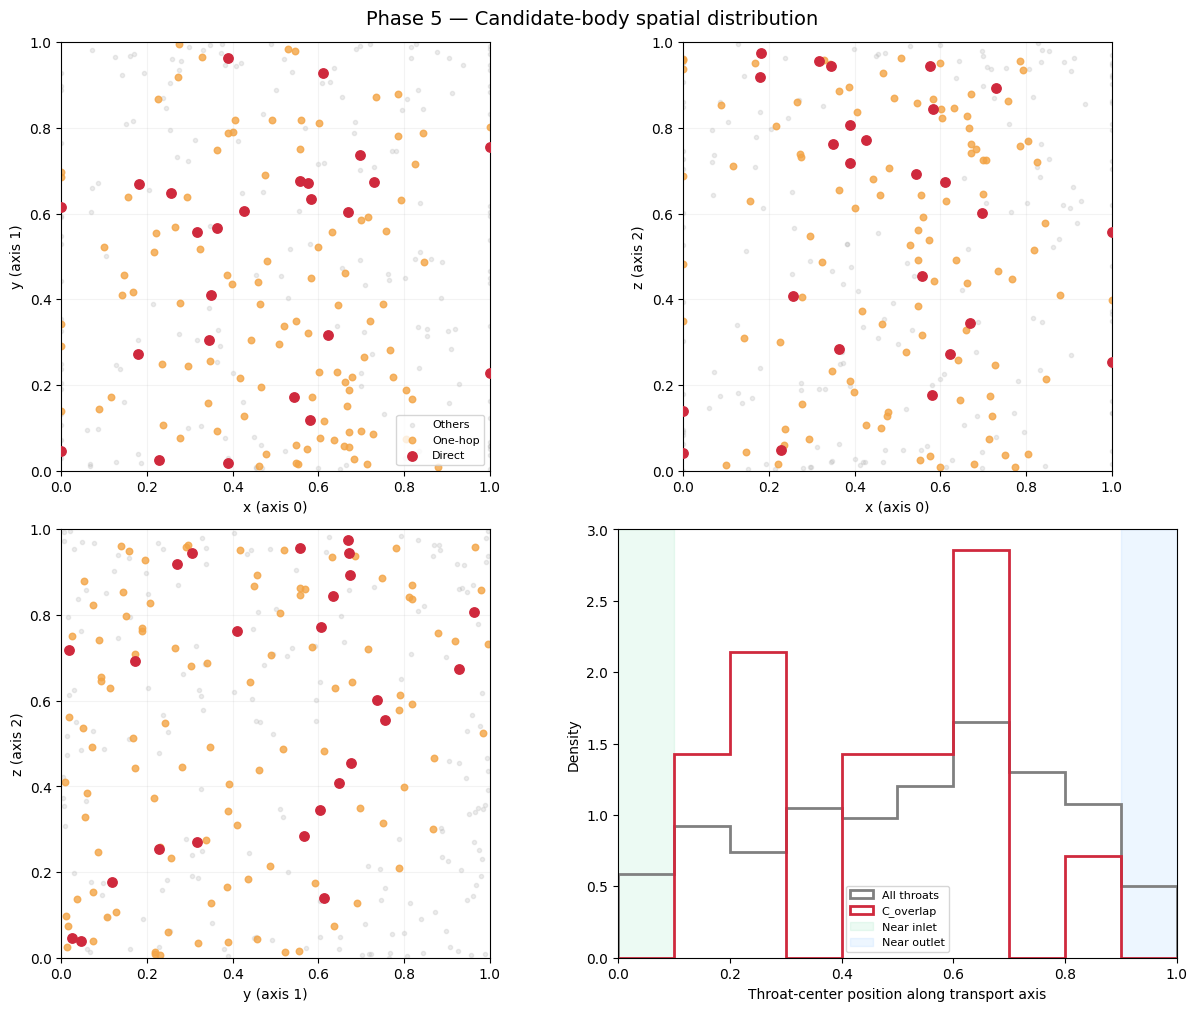

In [51]:
def phase5_plot_spatial_overview(
    body_df,
    neighbor_context,
    geometry,
    selected,
    group="C_overlap",
):
    """Three orthogonal spatial projections and flow-position histogram."""
    import numpy as np
    import matplotlib.pyplot as plt

    context = neighbor_context[
        neighbor_context.group == group
    ]

    onehop = set(
        context.loc[
            context.tier == "one_hop",
            "body_id",
        ].astype(int)
    )

    direct = set(
        body_df.index[
            body_df[f"in_{group}"]
        ].astype(int)
    )

    others = body_df.loc[
        ~body_df.index.isin(direct | onehop)
    ]

    neighbors = (
        body_df.loc[sorted(onehop)]
        if onehop else body_df.iloc[:0]
    )

    primary = (
        body_df.loc[sorted(direct)]
        if direct else body_df.iloc[:0]
    )

    fig, axs = plt.subplots(
        2, 2,
        figsize=(12, 10),
        constrained_layout=True,
    )

    pairs = [(0, 1), (0, 2), (1, 2)]
    labels = [
        "x (axis 0)",
        "y (axis 1)",
        "z (axis 2)",
    ]

    for ax, (p, q) in zip(
        axs.flat[:3], pairs
    ):
        for frame, color, size, alpha, name in [
            (others, "#b0b0b0", 9, 0.24, "Others"),
            (neighbors, "#f3a445", 22, 0.8, "One-hop"),
            (primary, "#cf293d", 46, 1.0, "Direct"),
        ]:
            if not len(frame):
                continue

            ax.scatter(
                frame[f"position_{p}"],
                frame[f"position_{q}"],
                c=color,
                s=size,
                alpha=alpha,
                label=name,
                zorder=4 if name == "Direct" else 2,
            )

        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_xlabel(labels[p])
        ax.set_ylabel(labels[q])
        ax.set_aspect("equal")
        ax.grid(alpha=0.15)

    axs[0, 0].legend(fontsize=8)

    # Compare selected throat locations against all throats
    ax = axs[1, 1]

    flow_axis = int(geometry["axis"])

    length = (
        geometry["merged_bodies"].shape[flow_axis] - 1
    )

    all_pos = (
        selected[f"center_{flow_axis}"]
        .to_numpy(float) / length
    )

    group_pos = (
        selected.loc[
            selected.group == group,
            f"center_{flow_axis}",
        ].to_numpy(float) / length
    )

    bins = np.linspace(0, 1, 11)

    if len(all_pos):
        ax.hist(
            all_pos,
            bins=bins,
            density=True,
            histtype="step",
            color="gray",
            linewidth=2,
            label="All throats",
        )

    if len(group_pos):
        ax.hist(
            group_pos,
            bins=bins,
            density=True,
            histtype="step",
            color="#cf293d",
            linewidth=2,
            label=group,
        )

    ax.axvspan(
        0, 0.1,
        color="#4bd08b",
        alpha=0.1,
        label="Near inlet",
    )

    ax.axvspan(
        0.9, 1.0,
        color="#51a9ff",
        alpha=0.1,
        label="Near outlet",
    )

    ax.set_xlim(0, 1)
    ax.set_xlabel(
        "Throat-center position along transport axis"
    )
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)

    fig.suptitle(
        "Phase 5 — Candidate-body spatial distribution",
        fontsize=14,
    )

    plt.show()
    return fig


fig_spatial = phase5_plot_spatial_overview(
    body_df,
    neighbor_context,
    geometry,
    selected,
    group="C_overlap",
)

In [113]:
def phase5_view_napari(
    run,
    geometry,
    selected,
    body_df,
    body_graph,
    group="C_overlap",
    selected_regions=None,
    region_id=None,
    show_context=False,
    show_links=False,
):
    """Explore actual candidate-body voxels and their one-hop neighbors."""
    import numpy as np
    import napari

    labels = np.asarray(
        geometry["merged_bodies"]
    )

    # ----------------------------------------
    # Select candidate throats
    # ----------------------------------------

    pick = selected.loc[
        selected.group == group
    ]

    if region_id is not None:
        if (
            selected_regions is None
            or "graph_region" not in selected_regions
        ):
            raise ValueError(
                "Pass selected_regions to focus on a region."
            )

        pick = selected_regions[
            (selected_regions.group == group)
            & (selected_regions.graph_region == region_id)
        ]

        if pick.empty:
            raise ValueError(
                f"No throats for region {region_id}."
            )

    primary = (
        set(
            pick[["body1_id", "body2_id"]]
            .to_numpy()
            .astype(int)
            .ravel()
        )
        if len(pick) else set()
    )

    if not primary:
        raise ValueError(
            f"No candidate throats for {group}."
        )

    # ----------------------------------------
    # One-hop bodies
    # ----------------------------------------

    onehop = (
        set().union(*(
            set(body_graph.neighbors(b))
            for b in primary
        )) - primary
    )

    direct = body_df.loc[sorted(primary)]

    nearest = (
        body_df.loc[sorted(onehop)]
        if onehop else body_df.iloc[:0]
    )

    # ----------------------------------------
    # Start napari
    # ----------------------------------------

    try:
        from IPython import get_ipython
        shell = get_ipython()

        if shell is not None:
            shell.run_line_magic("gui", "qt")
    except Exception:
        pass

    viewer = napari.Viewer(
        ndisplay=3,
        title=(
            f"Phase 5 — {group}"
            + (
                f" — region {region_id}"
                if region_id is not None else ""
            )
        ),
    )

    if show_context:
        viewer.add_image(
            (labels > 0).astype("uint8"),
            colormap="gray",
            opacity=0.06,
            rendering="translucent",
            name="All conducting voxels (faint)",
        )

    # ----------------------------------------
    # Real voxel geometry
    # ----------------------------------------

    direct_volume = np.isin(
        labels, list(primary)
    ).astype("uint8")

    neighbor_volume = np.isin(
        labels, list(onehop)
    ).astype("uint8")

    viewer.add_labels(
        neighbor_volume,
        opacity=0.35,
        name="One-hop neighbor bodies",
    )

    viewer.add_labels(
        direct_volume,
        opacity=0.65,
        name="Selected-throat bodies",
    )

    # ----------------------------------------
    # Clickable body centers and properties
    # ----------------------------------------

    for frame, name, color, size in [
        (
            nearest,
            "One-hop body centers",
            "#f3a445",
            4,
        ),
        (
            direct,
            "Selected body centers",
            "#cf293d",
            7,
        ),
    ]:
        if frame.empty:
            continue

        points = frame[
            ["center_0", "center_1", "center_2"]
        ].to_numpy(float)

        features = frame[[
            "body_id",
            "volume_voxels",
            "volume_RN",
            "coordination",
            "n_throats",
            "boundary_status",
            "is_articulation",
            "flow_position",
        ]].reset_index(drop=True)

        viewer.add_points(
            points,
            name=name,
            ndim=3,
            size=size,
            face_color=color,
            features=features,
        )

    # ----------------------------------------
    # Selected throat centers
    # ----------------------------------------

    tpoints = pick[
        ["center_0", "center_1", "center_2"]
    ].to_numpy(float)

    viewer.add_points(
        tpoints,
        ndim=3,
        size=5,
        face_color="#55deff",
        features=pick[[
            "throat_id",
            "C_geomean",
            "P_throat_fraction",
        ]].reset_index(drop=True),
        name=f"{group} throat centers",
    )

    # ----------------------------------------
    # Actual RN inlet and outlet nodes
    # ----------------------------------------

    for name, mask, color in [
        ("INLET (solved)", body_df.is_inlet, "#36de8b"),
        ("OUTLET (solved)", body_df.is_outlet, "#61a8ff"),
    ]:
        bd = body_df.loc[mask]

        if bd.empty:
            continue

        viewer.add_points(
            bd[[
                "center_0",
                "center_1",
                "center_2",
            ]].to_numpy(float),
            ndim=3,
            size=4,
            face_color=color,
            features=bd[[
                "body_id",
                "boundary_status",
                "coordination",
                "volume_voxels",
            ]].reset_index(drop=True),
            name=name,
        )

    # ----------------------------------------
    # Optional neighborhood graph connections
    # ----------------------------------------

    if show_links:
        lines = []

        for u in primary:
            for v in body_graph.neighbors(u):

                if v not in primary and v not in onehop:
                    continue

                p1 = body_df.loc[
                    u, ["center_0", "center_1", "center_2"]
                ].to_numpy(float)

                p2 = body_df.loc[
                    v, ["center_0", "center_1", "center_2"]
                ].to_numpy(float)

                lines.append(np.stack([p1, p2]))

        if lines:
            viewer.add_shapes(
                lines,
                shape_type="line",
                edge_width=0.8,
                name="Local body connections",
            )

    # ----------------------------------------
    # Bounding box
    # ----------------------------------------

    extent = np.asarray(
        labels.shape, float
    ) - 1

    x, y, z = extent

    corners = np.array([
        [0, 0, 0],
        [x, 0, 0],
        [0, y, 0],
        [0, 0, z],
        [x, y, 0],
        [x, 0, z],
        [0, y, z],
        [x, y, z],
    ])

    pairs = [
        (0, 1), (0, 2), (0, 3),
        (1, 4), (1, 5),
        (2, 4), (2, 6),
        (3, 5), (3, 6),
        (4, 7), (5, 7), (6, 7),
    ]

    viewer.add_shapes(
        [
            np.stack([corners[i], corners[j]])
            for i, j in pairs
        ],
        shape_type="line",
        edge_width=1,
        name="Volume bounding box",
    )

    # ----------------------------------------
    # Separate XYZ axes outside the box
    # ----------------------------------------

    length = float(max(labels.shape))

    axis_origin = (
        -np.ones(3) * 0.16 * length
    )

    axis_lines = []

    for k in range(3):
        endpoint = axis_origin.copy()
        endpoint[k] += 0.12 * length

        axis_lines.append(
            np.stack([axis_origin, endpoint])
        )

    viewer.add_shapes(
        axis_lines,
        shape_type="line",
        edge_color=[
            "red",
            "lime",
            "dodgerblue",
        ],
        edge_width=3,
        name="External XYZ axes",
    )

    viewer.axes.visible = True
    viewer.axes.labels = True
    viewer.dims.ndisplay = 3

    print(
        f"{group}: {len(pick)} selected throats, "
        f"{len(primary)} direct bodies, "
        f"{len(onehop)} one-hop bodies."
    )

    return viewer


viewer_phase5 = phase5_view_napari(
    run,
    geometry,
    selected,
    body_df,
    body_graph,
    group="C_overlap",
    selected_regions=selected_regions,
    region_id=None,
    show_context=False,
    show_links=False,
)

C_overlap: 47 selected throats, 67 direct bodies, 155 one-hop bodies.


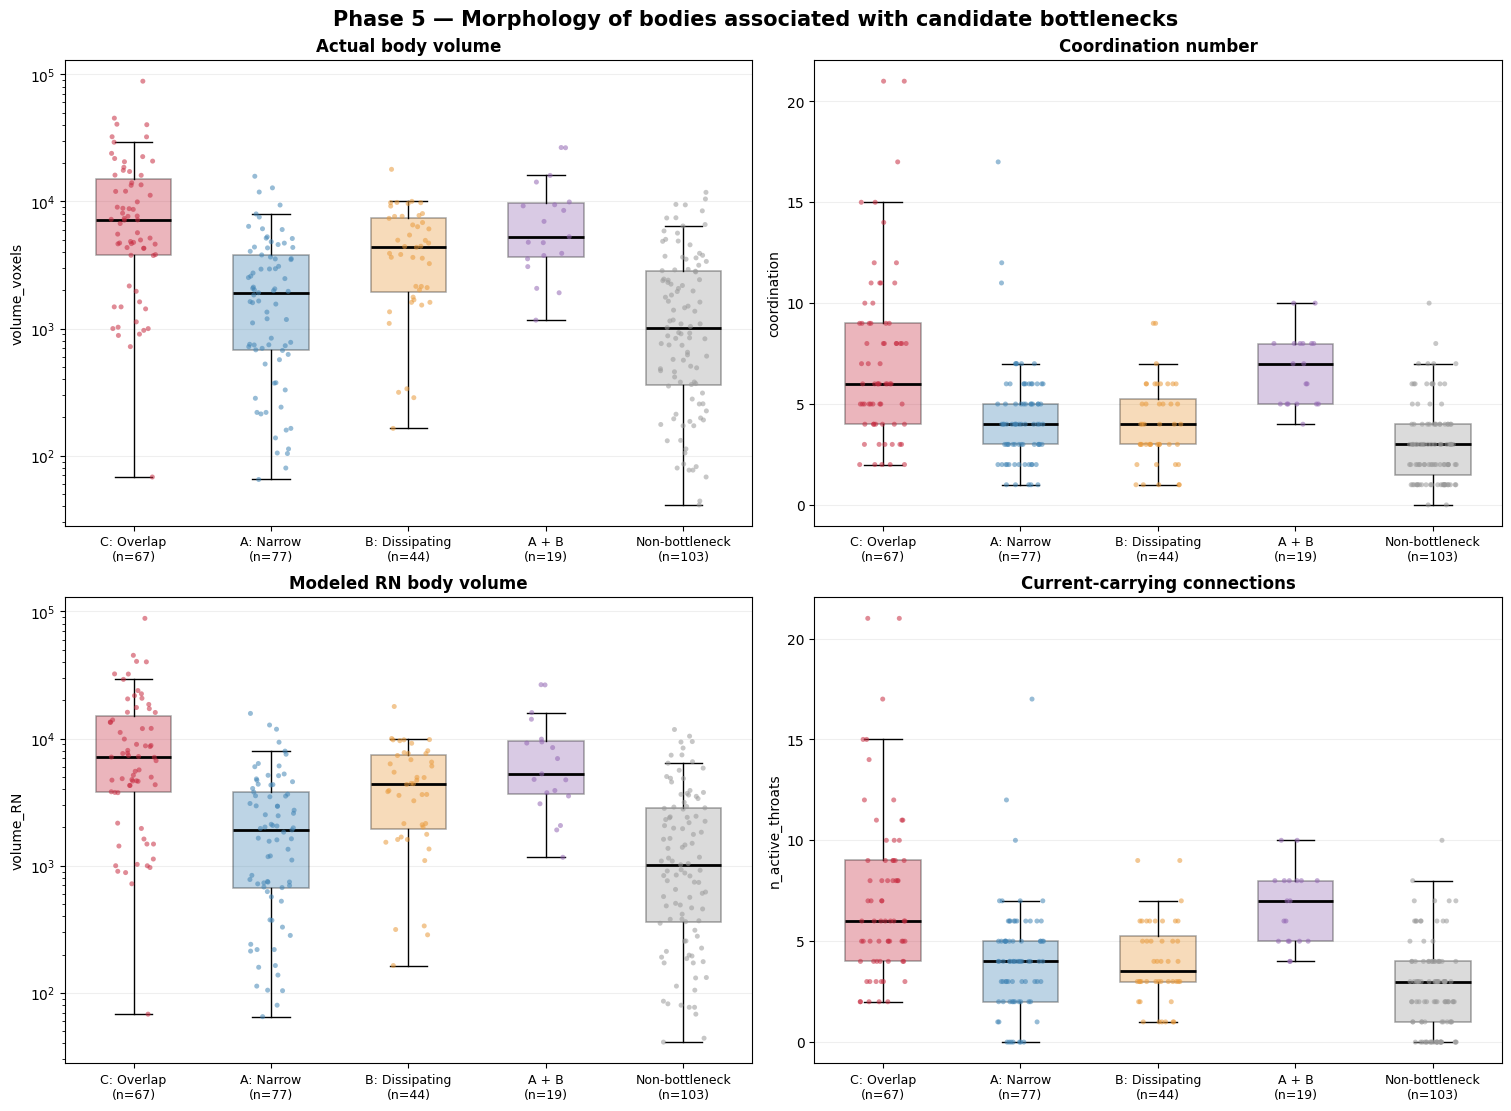


BODY MORPHOLOGY — DESCRIPTIVE STATISTICS


,metric,group,n,mean,std,median,Q1,Q3,IQR,p_vs_nonbottleneck,cliffs_delta
0,volume_voxels,C: Overlap,67,11558.7463,14093.3272,7156.0,3793.5,15028.50,11235.00,0.0000,0.6924
1,volume_voxels,A: Narrow,77,2729.4675,3041.0933,1914.0,673.0,3794.00,3121.00,0.0590,0.1648
2,volume_voxels,B: Dissipating,44,4896.7727,3621.3265,4387.5,1952.0,7426.00,5474.00,0.0000,0.5384
3,volume_voxels,A + B,19,8494.2105,7514.5384,5280.0,3644.0,9657.00,6013.00,0.0000,0.7394
4,volume_voxels,Non-bottleneck,103,2063.6019,2515.8497,1018.0,358.0,2839.50,2481.50,NaN,NaN
5,coordination,C: Overlap,67,7.2388,4.1891,6.0,4.0,9.00,5.00,0.0000,0.6925
6,coordination,A: Narrow,77,4.3117,2.5197,4.0,3.0,5.00,2.00,0.0001,0.3451
7,coordination,B: Dissipating,44,4.0000,1.9883,4.0,3.0,5.25,2.25,0.0039,0.2966
8,coordination,A + B,19,6.7368,1.7902,7.0,5.0,8.00,3.00,0.0000,0.8288
9,coordination,Non-bottleneck,103,3.0194,1.9452,3.0,1.5,4.00,2.50,NaN,NaN


In [114]:

def phase5_plot_body_morphology(body_df, figsize=(15, 11)):
    """
    Compare volumes, coordination, and transport-network properties
    of candidate-connected bodies versus noncandidate bodies.

    Returns
    -------
    fig : matplotlib.figure.Figure
    stats : pd.DataFrame
        N, mean, std, median, Q1, Q3, Mann-Whitney p-value
        and Cliff's delta relative to noncandidate bodies.
    """
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from scipy.stats import mannwhitneyu
    from IPython.display import display

    roles = [
        "C_overlap",
        "A_narrow_only",
        "B_dissipating_only",
        "A_and_B",
        "other",
    ]

    names = {
        "C_overlap": "C: Overlap",
        "A_narrow_only": "A: Narrow",
        "B_dissipating_only": "B: Dissipating",
        "A_and_B": "A + B",
        "other": "Non-bottleneck",
    }

    colors = {
        "C_overlap": "#c72c41",
        "A_narrow_only": "#4285b5",
        "B_dissipating_only": "#e99a3b",
        "A_and_B": "#9367b3",
        "other": "#9a9a9a",
    }

    roles = [
        r for r in roles
        if (body_df["body_role"] == r).any()
    ]

    metrics = [
        ("volume_voxels", "Actual body volume", True),
        ("coordination", "Coordination number", False),
        ("volume_RN", "Modeled RN body volume", True),
        ("n_active_throats", "Current-carrying connections", False),
    ]

    fig, axes = plt.subplots(
        2, 2, figsize=figsize, constrained_layout=True
    )

    rng = np.random.default_rng(42)
    records = []

    controls = body_df[
        body_df["body_role"] == "other"
    ]

    for ax, (column, title, log_scale) in zip(
        axes.flat, metrics
    ):
        arrays = []

        for role in roles:
            x = body_df.loc[
                body_df["body_role"] == role, column
            ].to_numpy(dtype=float)

            x = x[np.isfinite(x)]

            if log_scale:
                x = x[x > 0]

            arrays.append(x)

        positions = [
            i for i, x in enumerate(arrays, 1)
            if len(x) > 0
        ]

        valid_arrays = [
            x for x in arrays if len(x) > 0
        ]

        if valid_arrays:
            bp = ax.boxplot(
                valid_arrays,
                positions=positions,
                patch_artist=True,
                widths=0.55,
                showfliers=False,
                medianprops={
                    "color": "black",
                    "linewidth": 2,
                },
                boxprops={"linewidth": 1.1},
            )

            for patch, pos in zip(bp["boxes"], positions):
                patch.set_facecolor(
                    colors[roles[pos - 1]]
                )
                patch.set_alpha(0.35)

        # Plot individual bodies with horizontal jitter
        for i, (role, x) in enumerate(
            zip(roles, arrays), 1
        ):
            if len(x) == 0:
                continue

            sample = rng.choice(
                x,
                size=min(400, len(x)),
                replace=False,
            )

            jitter = rng.uniform(
                -0.17, 0.17, len(sample)
            )

            ax.scatter(
                np.full(len(sample), i) + jitter,
                sample,
                s=13,
                color=colors[role],
                alpha=0.55,
                edgecolors="none",
                zorder=3,
            )

        ax.set_xticks(
            range(1, len(roles) + 1)
        )

        ax.set_xticklabels([
            f"{names[r]}\n(n={len(arrays[i])})"
            for i, r in enumerate(roles)
        ], fontsize=9)

        if log_scale:
            ax.set_yscale("log")

        ax.set_title(title, fontsize=12, weight="bold")
        ax.set_ylabel(column)
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)

        # Descriptive statistics and exploratory effect sizes
        control = controls[column].to_numpy(float)
        control = control[np.isfinite(control)]

        if log_scale:
            control = control[control > 0]

        for role, x in zip(roles, arrays):
            if not len(x):
                continue

            p = np.nan
            cliffs_delta = np.nan

            if (
                role != "other"
                and len(control) > 0
            ):
                result = mannwhitneyu(
                    x, control,
                    alternative="two-sided"
                )

                p = float(result.pvalue)

                # Cliff's delta: -1 to +1
                cliffs_delta = (
                    2 * result.statistic
                    / (len(x) * len(control))
                    - 1
                )

            records.append({
                "metric": column,
                "group": names[role],
                "n": len(x),
                "mean": float(np.mean(x)),
                "std": float(np.std(x, ddof=1))
                    if len(x) > 1 else np.nan,
                "median": float(np.median(x)),
                "Q1": float(np.percentile(x, 25)),
                "Q3": float(np.percentile(x, 75)),
                "IQR": float(
                    np.percentile(x, 75)
                    - np.percentile(x, 25)
                ),
                "p_vs_nonbottleneck": p,
                "cliffs_delta": cliffs_delta,
            })

    fig.suptitle(
        "Phase 5 — Morphology of bodies associated "
        "with candidate bottlenecks",
        fontsize=15,
        weight="bold",
    )

    plt.show()

    stats = pd.DataFrame(records)

    print("\nBODY MORPHOLOGY — DESCRIPTIVE STATISTICS")
    display(stats.round(4))

    return fig, stats


fig_body, body_stats = phase5_plot_body_morphology(
    body_df
)


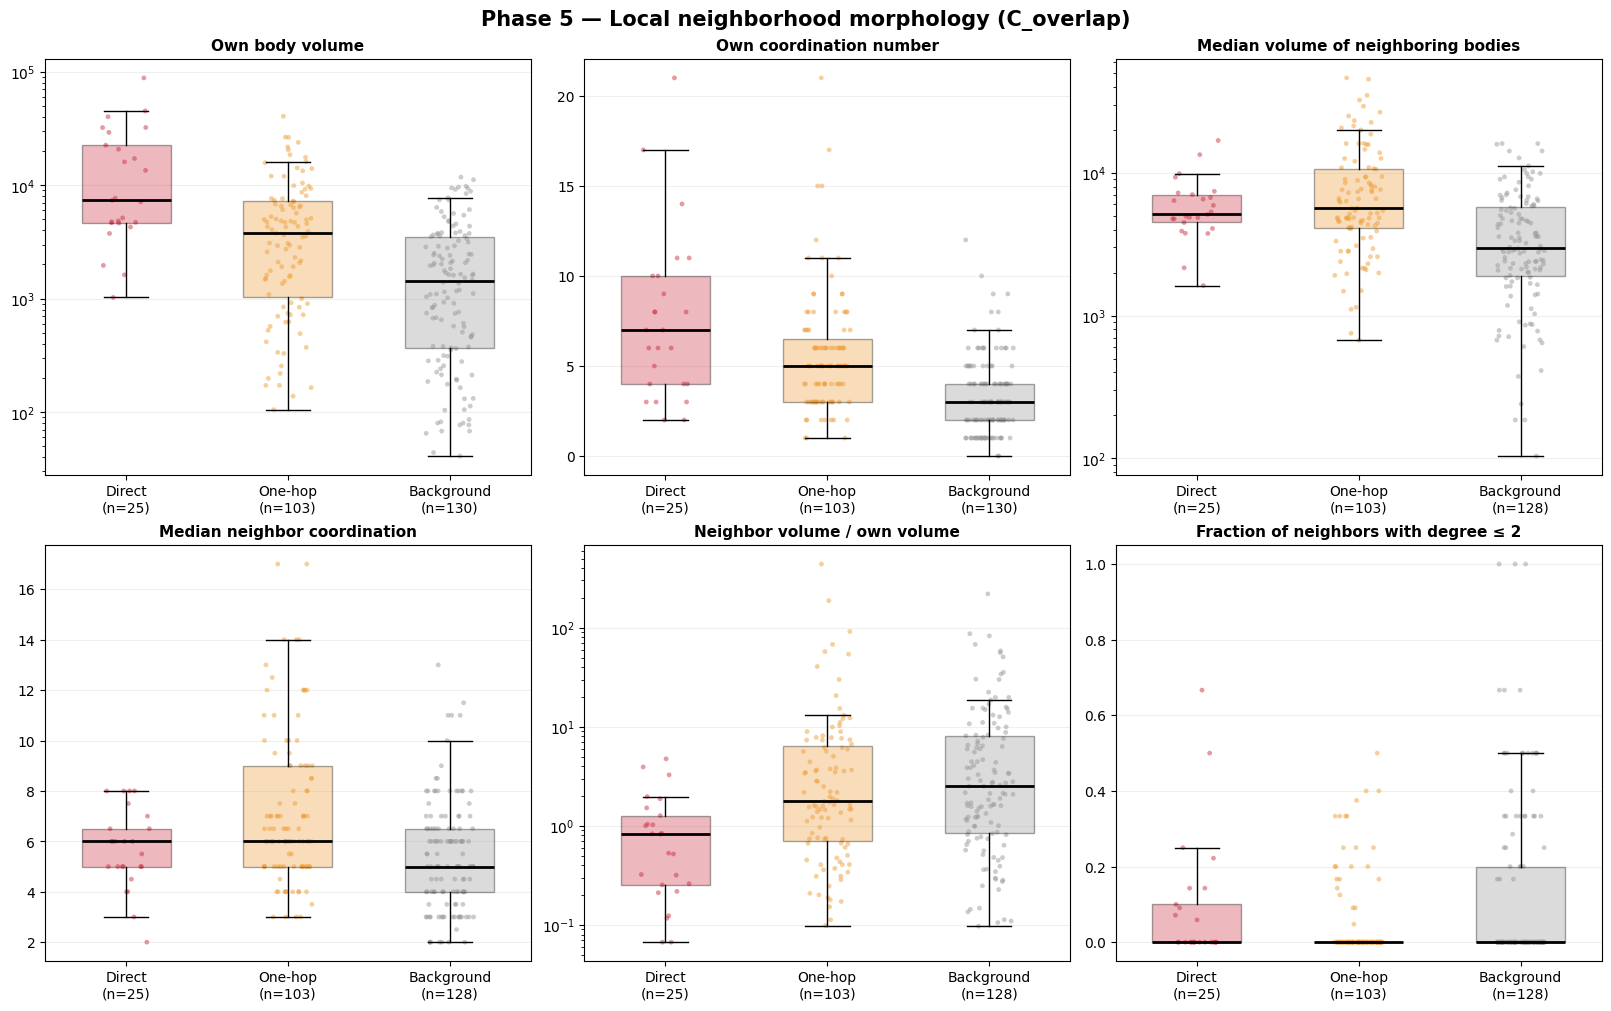


ONE-HOP NEIGHBORHOOD STATISTICS


,metric,population,n,median,Q1,Q3,mean,std
0,volume_voxels,Direct,25,7359.000,4657.000,22512.000,16831.520,19685.982
1,volume_voxels,One-hop,103,3771.000,1043.500,7193.000,5777.078,6880.444
2,volume_voxels,Background,130,1426.500,364.500,3478.250,2361.100,2705.024
3,coordination,Direct,25,7.000,4.000,10.000,7.560,4.682
4,coordination,One-hop,103,5.000,3.000,6.500,5.602,3.297
5,coordination,Background,130,3.000,2.000,4.000,3.269,2.138
6,neighbor_volume_median,Direct,25,5108.000,4487.000,7031.000,6199.960,3320.483
7,neighbor_volume_median,One-hop,103,5632.000,4077.250,10638.250,8959.806,8745.135
8,neighbor_volume_median,Background,128,2975.250,1897.875,5728.375,4211.945,3501.877
9,neighbor_coordination_median,Direct,25,6.000,5.000,6.500,5.700,1.568


In [52]:

def phase5_plot_neighborhood_morphology(
    body_df,
    neighbor_context,
    neighbor_profiles,
    group="C_overlap",
    figsize=(16, 10),
):
    """
    Compare direct candidate bodies, one-hop bodies,
    and noncandidate background bodies.

    All three plotted populations are disjoint.

    Returns
    -------
    fig, stats
    """
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from IPython.display import display

    ctx = neighbor_context.loc[
        neighbor_context["group"] == group
    ]

    direct_ids = set(
        ctx.loc[
            ctx["tier"] == "direct", "body_id"
        ].astype(int)
    )

    onehop_ids = set(
        ctx.loc[
            ctx["tier"] == "one_hop", "body_id"
        ].astype(int)
    ) - direct_ids

    background_ids = set(
        body_df.index[
            body_df["candidate_groups"] == 0
        ].astype(int)
    ) - direct_ids - onehop_ids

    # Merge existing body and one-hop profile information
    neighbor_columns = [
        "neighbor_volume_median",
        "neighbor_coordination_median",
        "neighbor_volume_ratio",
        "neighbor_frac_degree_le2",
        "neighbor_frac_articulation",
        "neighbor_frac_candidate",
    ]

    data = body_df.join(
        neighbor_profiles[neighbor_columns],
        how="left",
    )

    populations = {
        "Direct": data.loc[sorted(direct_ids)],
        "One-hop": data.loc[sorted(onehop_ids)],
        "Background": data.loc[sorted(background_ids)],
    }

    colors = {
        "Direct": "#ce3445",
        "One-hop": "#efa03c",
        "Background": "#9a9a9a",
    }

    metrics = [
        ("volume_voxels", "Own body volume", True),
        ("coordination", "Own coordination number", False),

        (
            "neighbor_volume_median",
            "Median volume of neighboring bodies",
            True,
        ),
        (
            "neighbor_coordination_median",
            "Median neighbor coordination",
            False,
        ),
        (
            "neighbor_volume_ratio",
            "Neighbor volume / own volume",
            True,
        ),
        (
            "neighbor_frac_degree_le2",
            "Fraction of neighbors with degree ≤ 2",
            False,
        ),
    ]

    fig, axs = plt.subplots(
        2, 3, figsize=figsize, constrained_layout=True
    )

    rng = np.random.default_rng(11)
    rows = []

    for ax, (column, title, log_scale) in zip(
        axs.flat, metrics
    ):
        values = []

        for name, frame in populations.items():
            x = frame[column].to_numpy(float)
            x = x[np.isfinite(x)]

            if log_scale:
                x = x[x > 0]

            values.append(x)

        positions = [
            i for i, x in enumerate(values, 1)
            if len(x)
        ]

        if positions:
            bp = ax.boxplot(
                [values[i - 1] for i in positions],
                positions=positions,
                widths=0.55,
                patch_artist=True,
                showfliers=False,
                medianprops={
                    "color": "black",
                    "linewidth": 2,
                },
            )

            names = list(populations)

            for patch, pos in zip(bp["boxes"], positions):
                patch.set_facecolor(
                    colors[names[pos - 1]]
                )
                patch.set_alpha(0.35)

        for i, ((name, frame), x) in enumerate(
            zip(populations.items(), values), 1
        ):
            if not len(x):
                continue

            draw = rng.choice(
                x,
                min(len(x), 300),
                replace=False,
            )

            jitter = rng.uniform(
                -0.15, 0.15, len(draw)
            )

            ax.scatter(
                i + jitter,
                draw,
                s=12,
                alpha=0.5,
                color=colors[name],
                edgecolors="none",
            )

        ax.set_xticks([1, 2, 3])
        ax.set_xticklabels([
            f"{name}\n(n={len(values[i])})"
            for i, name in enumerate(populations)
        ])

        if log_scale:
            ax.set_yscale("log")

        ax.set_title(title, fontsize=11, weight="bold")
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)

        for (name, frame), x in zip(
            populations.items(), values
        ):
            if not len(x):
                continue

            rows.append({
                "metric": column,
                "population": name,
                "n": len(x),
                "median": np.median(x),
                "Q1": np.percentile(x, 25),
                "Q3": np.percentile(x, 75),
                "mean": np.mean(x),
                "std": (
                    np.std(x, ddof=1)
                    if len(x) > 1 else np.nan
                ),
            })

    fig.suptitle(
        f"Phase 5 — Local neighborhood morphology ({group})",
        fontsize=15,
        weight="bold",
    )

    plt.show()

    stats = pd.DataFrame(rows)

    print("\nONE-HOP NEIGHBORHOOD STATISTICS")
    display(stats.round(3))

    return fig, stats


fig_neighbors, neighbor_stats = (
    phase5_plot_neighborhood_morphology(
        body_df,
        neighbor_context,
        neighbor_profiles,
        group="C_overlap",
    )
)


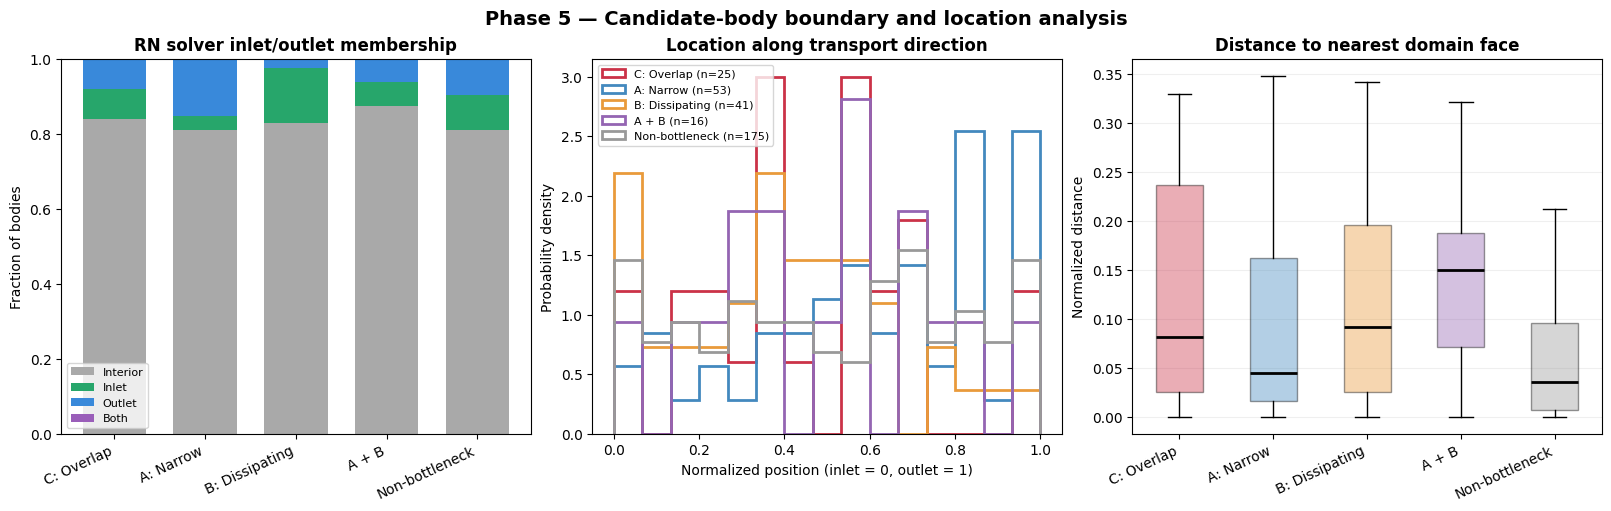


BOUNDARY AND LOCATION STATISTICS


,group,n,fraction_inlet,fraction_outlet,fraction_touching_face,median_flow_position,median_distance_to_face,fraction_in_first_10pct,fraction_in_last_10pct
0,C: Overlap,25,0.080,0.080,0.160,0.427,0.081,0.080,0.080
1,A: Narrow,53,0.038,0.151,0.189,0.663,0.044,0.057,0.189
2,B: Dissipating,41,0.146,0.024,0.171,0.392,0.092,0.146,0.024
3,A + B,16,0.062,0.062,0.125,0.515,0.150,0.062,0.062
4,Non-bottleneck,175,0.091,0.097,0.189,0.533,0.036,0.143,0.131


In [53]:

def phase5_plot_boundary_and_location(
    body_df,
    figsize=(16, 5),
):
    """Plot solver boundary membership and spatial distributions."""
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from IPython.display import display

    groups = [
        ("C_overlap", "C: Overlap", "#cb3248"),
        ("A_narrow_only", "A: Narrow", "#4389be"),
        ("B_dissipating_only", "B: Dissipating", "#e99a3b"),
        ("A_and_B", "A + B", "#9465b2"),
        ("other", "Non-bottleneck", "#999999"),
    ]

    groups = [
        (role, name, color)
        for role, name, color in groups
        if (body_df.body_role == role).any()
    ]

    fig, axes = plt.subplots(
        1, 3, figsize=figsize, constrained_layout=True
    )

    summary = []

    # ------------------------------------------
    # Plot 1: Solver inlet/outlet status
    # ------------------------------------------
    ax = axes[0]

    bottom = np.zeros(len(groups))

    statuses = [
        ("interior", "#a9a9a9"),
        ("inlet", "#27a66b"),
        ("outlet", "#3989da"),
        ("both", "#9a5eb9"),
    ]

    for status, color in statuses:
        values = []

        for role, name, c in groups:
            d = body_df[body_df.body_role == role]
            values.append(
                (d.boundary_status == status).mean()
            )

        ax.bar(
            range(len(groups)),
            values,
            bottom=bottom,
            color=color,
            label=status.capitalize(),
            width=0.7,
        )

        bottom += np.asarray(values)

    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels(
        [name for _, name, _ in groups],
        rotation=25,
        ha="right",
    )

    ax.set_ylim(0, 1)
    ax.set_ylabel("Fraction of bodies")
    ax.set_title(
        "RN solver inlet/outlet membership",
        weight="bold",
    )
    ax.legend(fontsize=8)

    # ------------------------------------------
    # Plot 2: Position along transport direction
    # ------------------------------------------
    ax = axes[1]

    bins = np.linspace(0, 1, 16)

    for role, name, color in groups:
        d = body_df[body_df.body_role == role]

        ax.hist(
            d.flow_position,
            bins=bins,
            density=True,
            histtype="step",
            linewidth=2,
            color=color,
            label=f"{name} (n={len(d)})",
        )

    ax.set_xlabel(
        "Normalized position (inlet = 0, outlet = 1)"
    )
    ax.set_ylabel("Probability density")
    ax.set_title(
        "Location along transport direction",
        weight="bold",
    )
    ax.legend(fontsize=8)

    # ------------------------------------------
    # Plot 3: Distance to nearest domain face
    # ------------------------------------------
    ax = axes[2]

    values = [
        body_df.loc[
            body_df.body_role == role,
            "distance_to_any_face",
        ].dropna().to_numpy()
        for role, _, _ in groups
    ]

    bp = ax.boxplot(
        values,
        patch_artist=True,
        showfliers=False,
        medianprops={
            "color": "black",
            "linewidth": 2,
        },
    )

    for patch, (_, _, color) in zip(
        bp["boxes"], groups
    ):
        patch.set_facecolor(color)
        patch.set_alpha(0.4)

    ax.set_xticks(range(1, len(groups) + 1))
    ax.set_xticklabels(
        [name for _, name, _ in groups],
        rotation=25,
        ha="right",
    )

    ax.set_ylabel("Normalized distance")
    ax.set_title(
        "Distance to nearest domain face",
        weight="bold",
    )
    ax.grid(axis="y", alpha=0.2)

    # ------------------------------------------
    # Summary
    # ------------------------------------------
    for role, name, color in groups:
        d = body_df[body_df.body_role == role]

        summary.append({
            "group": name,
            "n": len(d),

            "fraction_inlet": d.is_inlet.mean(),
            "fraction_outlet": d.is_outlet.mean(),

            "fraction_touching_face": (
                d.touches_inlet_face
                | d.touches_outlet_face
            ).mean(),

            "median_flow_position":
                d.flow_position.median(),

            "median_distance_to_face":
                d.distance_to_any_face.median(),

            "fraction_in_first_10pct": (
                d.flow_position < 0.1
            ).mean(),

            "fraction_in_last_10pct": (
                d.flow_position > 0.9
            ).mean(),
        })

    fig.suptitle(
        "Phase 5 — Candidate-body boundary and location analysis",
        fontsize=14,
        weight="bold",
    )

    plt.show()

    summary = pd.DataFrame(summary)

    print("\nBOUNDARY AND LOCATION STATISTICS")
    display(summary.round(3))

    return fig, summary


fig_location, location_stats = (
    phase5_plot_boundary_and_location(body_df)
)


## Phase 6 - Throat Changes

In [54]:
def phase6_solve(ctx, g):
    """Physical two-terminal RN conductance, including disconnected networks."""
    import numpy as np
    import scipy.sparse as sp
    from scipy.sparse.csgraph import connected_components
    from scipy.sparse.linalg import spsolve

    g = np.asarray(g, float)
    conns = ctx["conns"]
    n = ctx["n_bodies"]
    inlet, outlet = ctx["inlet"], ctx["outlet"]
    dv = ctx["delta_V"]

    if g.shape != (len(conns),):
        raise ValueError("Conductance vector has wrong shape.")
    if np.any(g < 0) or not np.all(np.isfinite(g)):
        raise ValueError("Conductances must be finite and nonnegative.")

    valid = (conns >= 0).all(axis=1) & (g > 0)
    i, j = conns[valid].T
    gg = g[valid]

    # Identify connected components after intervention
    graph = sp.csr_matrix(
        (
            np.ones(2 * len(i)),
            (np.r_[i, j], np.r_[j, i]),
        ),
        shape=(n, n),
    )

    _, component = connected_components(
        graph, directed=False
    )

    v = np.zeros(n, float)
    v[inlet] = dv

    present_in = set(component[inlet])
    present_out = set(component[outlet])

    both = present_in & present_out
    only_in = present_in - present_out

    # A component connected only to the inlet is
    # equipotential at the inlet voltage.
    v[np.isin(component, list(only_in))] = dv

    active = np.isin(component, list(both))

    known = np.zeros(n, bool)
    known[inlet] = True
    known[outlet] = True

    free = np.where(active & ~known)[0]

    if len(free):
        diag = np.bincount(
            np.r_[i, j],
            weights=np.r_[gg, gg],
            minlength=n,
        )

        lap = sp.csr_matrix(
            (
                np.r_[-gg, -gg, diag],
                (
                    np.r_[i, j, np.arange(n)],
                    np.r_[j, i, np.arange(n)],
                ),
            ),
            shape=(n, n),
        )

        bound = np.where(active & known)[0]

        v[free] = spsolve(
            lap[free][:, free],
            -lap[free][:, bound] @ v[bound],
        )

    currents = np.zeros_like(g)
    currents[valid] = gg * (v[i] - v[j])

    # P_total = G_eff * delta_V**2
    # This avoids double-counting terminal-adjacent edges.
    geff = float(
        np.sum(gg * (v[i] - v[j])**2) / dv**2
    )

    return geff, v, currents

In [55]:
def phase6_prepare(run, geometry, selected):
    """Prepare and validate the original Berg three-resistor network."""
    import numpy as np
    import berg_cc

    a = run["saved"]["arrays"]
    sigma = float(run["config"].get("sigma", 1.0))

    g, resistance = berg_cc.calculate_conductances(
        a, sigma=sigma, verbose=False
    )

    inlet, outlet = berg_cc.get_inlet_outlet_indices(
        a,
        geometry["merged_bodies"],
        direction=run["config"].get("direction", "x"),
    )

    inlet = np.asarray(inlet, int)
    outlet = np.asarray(outlet, int)

    if (
        not len(inlet)
        or not len(outlet)
        or np.intersect1d(inlet, outlet).size
    ):
        raise ValueError("Invalid inlet/outlet boundary nodes.")

    tids = np.asarray(a["throat_ids"], int)
    conns = np.asarray(a["conns"], int)

    if np.any(conns < 0):
        raise ValueError(
            "Invalid saved body connections; inspect before perturbing."
        )

    if len(tids) != len(np.unique(tids)):
        raise ValueError("Duplicate throat IDs.")

    if (
        selected["throat_id"].duplicated().any()
        or not set(selected.throat_id).issubset(set(tids))
    ):
        raise ValueError(
            "Selected table has missing or duplicate throat IDs."
        )

    ctx = {
        "conns": conns,
        "n_bodies": len(a["body_ids"]),
        "inlet": inlet,
        "outlet": outlet,

        "delta_V": float(
            run["config"].get("delta_V", 1.0)
        ),

        "g_base": np.asarray(g, float),
        "R1": np.asarray(resistance["R1"], float),
        "R2": np.asarray(resistance["R2"], float),
        "Rt": np.asarray(resistance["R_throat"], float),

        "area": np.asarray(a["throat_area"], float),
        "length": np.asarray(a["L_throat"], float),
        "throat_volume": np.asarray(
            a["throat_volume"], float
        ),

        "throat_ids": tids,
        "rows": {
            int(t): k for k, t in enumerate(tids)
        },

        "pore_volume": int(
            np.count_nonzero(geometry["merged_bodies"])
        ),
        "domain_volume": int(
            np.prod(geometry["merged_bodies"].shape)
        ),
    }

    if ctx["delta_V"] == 0:
        raise ValueError("delta_V cannot be zero.")

    G0, potential, I0 = phase6_solve(
        ctx, ctx["g_base"]
    )

    Isaved = np.asarray(
        run["saved"]["current"], float
    )

    error = np.max(np.abs(I0 - Isaved)) / max(
        float(np.max(np.abs(Isaved))), 1e-30
    )

    G_saved_energy = (
        np.sum(Isaved**2 / ctx["g_base"])
        / ctx["delta_V"]**2
    )

    ctx["G0"] = G0
    ctx["G0_saved_energy"] = float(G_saved_energy)
    ctx["current_error_relmax"] = float(error)

    print(f"Baseline physical G_eff:   {G0:.8g}")
    print(f"Saved-current energy G:   {G_saved_energy:.8g}")
    print(f"Maximum relative current discrepancy: {error:.2e}")
    print(f"Number of inlet bodies:  {len(inlet)}")
    print(f"Number of outlet bodies: {len(outlet)}")

    if error > 1e-4:
        raise RuntimeError(
            "Reconstructed currents differ from the saved solution. "
            "Check boundary conditions and model version before proceeding."
        )

    if G0 <= 0:
        raise ValueError("Baseline effective conductance is zero.")

    return ctx


phase6_ctx = phase6_prepare(run, geometry, selected)

Baseline physical G_eff:   15.705543
Saved-current energy G:   15.705543
Maximum relative current discrepancy: 5.82e-15
Number of inlet bodies:  27
Number of outlet bodies: 29


In [84]:
def phase6_run_sets(
    ctx,
    selected,
    n_random=200,
    area_increase=0.10,
    seed=42,
    equal_volume=True,
):
    """
    Improve or block all N C throats and random N-throat controls.

    Interventions
    -------------
    widen_20pct:
        Increase every selected throat area by area_increase.

    widen_equal_volume:
        Add exactly the same modeled throat volume
        as the C-overlap widening intervention.

    block:
        Set conductances of selected connections to zero.

    Returns
    -------
    results : pd.DataFrame
        Every individual random trial and intervention.

    summary : pd.DataFrame
        Median response and 5th/95th percentiles.
    """
    import numpy as np
    import pandas as pd

    if area_increase <= 0:
        raise ValueError("area_increase must be positive.")

    if n_random < 1:
        raise ValueError("n_random must be positive.")

    rng = np.random.default_rng(seed)

    st = selected.set_index("throat_id")
    tids = ctx["throat_ids"]

    groups = st.reindex(tids)["group"].to_numpy()

    C = np.where(groups == "C_overlap")[0]

    if C.size == 0:
        raise ValueError("No C_overlap throats in selected.")

    N = len(C)

    # Exclude all edges incident to C-connected bodies
    # when constructing geographically separate controls.
    c_nodes = set(
        ctx["conns"][C].ravel().tolist()
    )

    outside = np.array([
        (i not in c_nodes) and (j not in c_nodes)
        for i, j in ctx["conns"]
    ])

    pools = {
        "A_narrow_only": np.where(
            groups == "A_narrow_only"
        )[0],

        "B_dissipating_only": np.where(
            groups == "B_dissipating_only"
        )[0],

        "Other_far_from_C": np.where(
            (groups == "other") & outside
        )[0],

        "All_nonC_far_from_C": np.where(
            (groups != "C_overlap") & outside
        )[0],
    }

    print(f"Number of C throats: N = {N}")
    print(f"Random samples per control: {n_random}")
    print("\nAvailable control pools:")

    for name, pool in pools.items():
        print(f"  {name}: {len(pool)}")

        if len(pool) < N:
            raise ValueError(
                f"{name} contains only {len(pool)} throats "
                f"but C contains {N}. Cannot sample equal N "
                "without replacement."
            )

    # Modeled equivalent throat volume = A_t * L_t
    unit_volume = ctx["area"] * ctx["length"]

    # Reference volume added by widening ALL C throats
    volume_C = float(
        area_increase * np.sum(unit_volume[C])
    )

    R_body = ctx["R1"] + ctx["R2"]

    rows = []

    def evaluate(category, sample, trial):
        sample = np.sort(
            np.asarray(sample, dtype=int)
        )

        selected_ids = tuple(
            int(v) for v in tids[sample]
        )

        base_volume = float(
            np.sum(unit_volume[sample])
        )

        stored_throat_volume = float(
            np.sum(ctx["throat_volume"][sample])
        )

        for intervention in (
            "widen_20pct",
            "widen_equal_volume",
            "block",
        ):
            if (
                intervention == "widen_equal_volume"
                and not equal_volume
            ):
                continue

            g = ctx["g_base"].copy()

            if intervention == "widen_20pct":
                alpha = area_increase

            elif intervention == "widen_equal_volume":
                alpha = (
                    volume_C / base_volume
                    if base_volume > 0 else 0.0
                )

            else:
                alpha = 0.0

            if intervention == "block":
                # Remove entire body-to-body connection
                g[sample] = 0.0

                delta_volume = 0.0
                delta_stored_proxy = 0.0

            else:
                # A_t' = (1 + alpha) * A_t
                # R_t' = R_t / (1 + alpha)
                #
                # Body resistors remain unchanged.
                g[sample] = 1.0 / (
                    R_body[sample]
                    + ctx["Rt"][sample] / (1 + alpha)
                )

                delta_volume = float(
                    alpha * base_volume
                )

                delta_stored_proxy = float(
                    alpha * stored_throat_volume
                )

            G_new, _, _ = phase6_solve(ctx, g)

            change = 100.0 * (
                G_new / ctx["G0"] - 1.0
            )

            # Both reported as positive importance:
            # widening -> gain; blocking -> loss.
            importance = (
                -change
                if intervention == "block"
                else change
            )

            added_porosity_pp = (
                100.0 * delta_volume
                / ctx["domain_volume"]
            )

            rows.append({
                "group": category,
                "trial": trial,
                "intervention": intervention,

                "n_throats": N,
                "throat_ids": selected_ids,

                "G_eff": G_new,
                "delta_G_pct": change,
                "importance_pct": importance,

                "area_increase": alpha,

                "volume_added_model": delta_volume,
                "volume_added_stored_proxy":
                    delta_stored_proxy,

                "volume_added_pct_pore": (
                    100.0 * delta_volume
                    / ctx["pore_volume"]
                ),

                "porosity_increase_pp": added_porosity_pp,

                "added_volume_ratio_to_C": (
                    delta_volume / volume_C
                    if intervention != "block"
                    else 0.0
                ),

                # Hypothetical volume if we physically
                # replaced entire selected throats by solid.
                # NOT an actual change in the RN-only block test.
                "hypothetical_full_plug_volume": (
                    stored_throat_volume
                    if intervention == "block"
                    else 0.0
                ),

                "gain_per_porosity_pp": (
                    change / added_porosity_pp
                    if intervention != "block"
                    and added_porosity_pp > 0
                    else np.nan
                ),
            })

    # Deterministic experiment: all C throats
    evaluate("C_overlap", C, trial=0)

    # Random experiments: equal N in each pool
    for name, pool in pools.items():
        for trial in range(n_random):
            sample = rng.choice(
                pool, N, replace=False
            )
            evaluate(name, sample, trial)

    results = pd.DataFrame(rows)

    summary = (
        results.groupby(
            ["intervention", "group"],
            sort=False,
        )
        .agg(
            n_trials=("trial", "size"),

            median_effect_pct=(
                "importance_pct", "median"
            ),

            p05_effect_pct=(
                "importance_pct",
                lambda x: x.quantile(0.05),
            ),

            p95_effect_pct=(
                "importance_pct",
                lambda x: x.quantile(0.95),
            ),

            median_added_volume=(
                "volume_added_model", "median"
            ),

            median_added_porosity_pp=(
                "porosity_increase_pp", "median"
            ),
        )
        .reset_index()
    )

    print("\nPHASE 6 — INTERVENTION SUMMARY")
    display(summary.round(5))

    return results, summary


phase6_results, phase6_summary = phase6_run_sets(
    phase6_ctx,
    selected,
    n_random=200,
    area_increase=0.20,
    seed=10,
    equal_volume=True,
)

Number of C throats: N = 14
Random samples per control: 200

Available control pools:
  A_narrow_only: 55
  B_dissipating_only: 55
  Other_far_from_C: 481
  All_nonC_far_from_C: 551

PHASE 6 — INTERVENTION SUMMARY


,intervention,group,n_trials,median_effect_pct,p05_effect_pct,p95_effect_pct,median_added_volume,median_added_porosity_pp
0,widen_20pct,C_overlap,1,0.78276,0.78276,0.78276,1102.40428,0.03266
1,widen_equal_volume,C_overlap,1,0.78276,0.78276,0.78276,1102.40428,0.03266
2,block,C_overlap,1,7.85833,7.85833,7.85833,0.00000,0.00000
3,widen_20pct,A_narrow_only,200,0.13169,0.09172,0.17206,410.21357,0.01215
4,widen_equal_volume,A_narrow_only,200,0.30109,0.18930,0.52747,1102.40428,0.03266
5,block,A_narrow_only,200,1.34778,0.94000,1.80915,0.00000,0.00000
6,widen_20pct,B_dissipating_only,200,0.79699,0.65565,0.97761,2999.59692,0.08888
7,widen_equal_volume,B_dissipating_only,200,0.31862,0.22291,0.47273,1102.40428,0.03266
8,block,B_dissipating_only,200,15.50764,12.34128,20.17300,0.00000,0.00000
9,widen_20pct,Other_far_from_C,200,0.06608,0.03921,0.11233,1253.41071,0.03714


In [80]:
body_array = np.asarray(geometry["merged_bodies"], int)

In [81]:
seg = (body_array>0)

In [82]:
seg.sum()/seg.size

0.46637155555555554

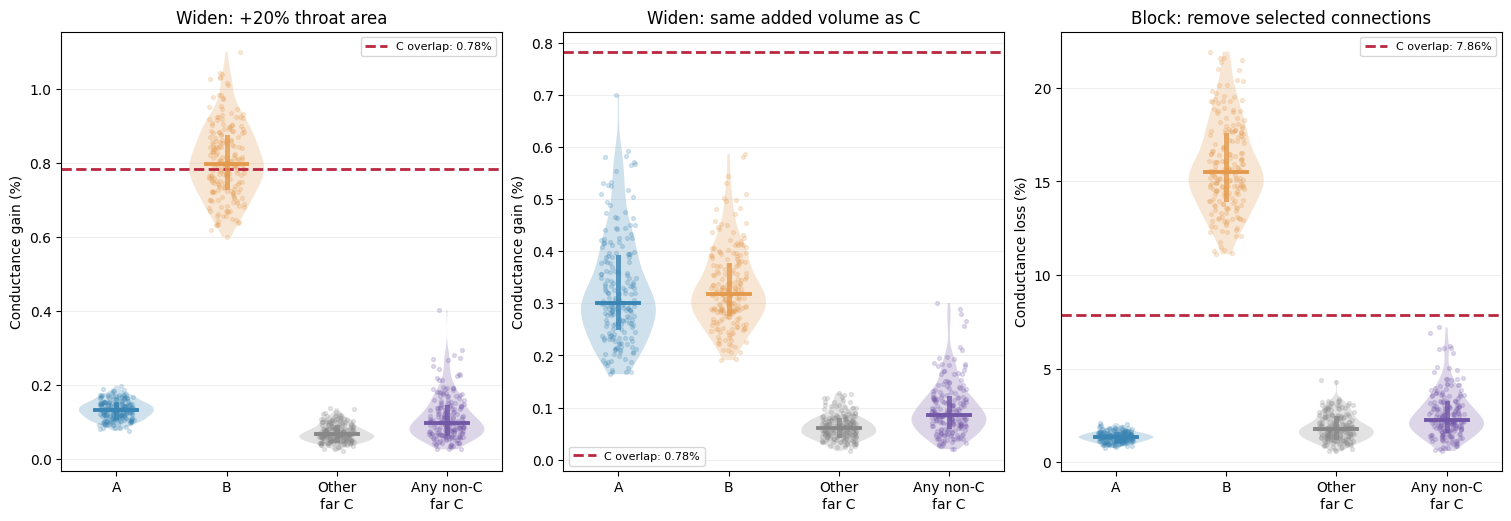

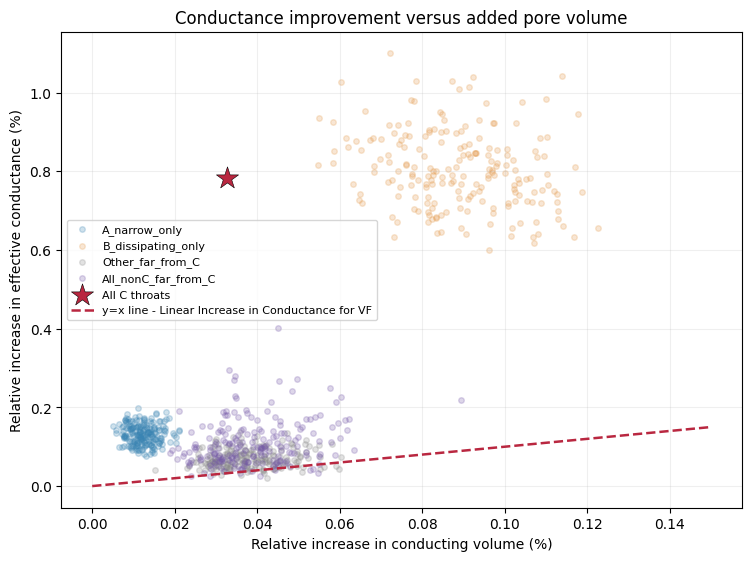


RANDOM CONTROL COMPARISON
p_random_ge_C = fraction of random draws at least as effective as C (with +1 correction).


,intervention,control,n_draws,C_effect_pct,control_median_pct,p_random_ge_C
0,widen_20pct,A_narrow_only,200,0.7828,0.1317,0.0050
1,widen_20pct,B_dissipating_only,200,0.7828,0.7970,0.5622
2,widen_20pct,Other_far_from_C,200,0.7828,0.0661,0.0050
3,widen_20pct,All_nonC_far_from_C,200,0.7828,0.0966,0.0050
4,widen_equal_volume,A_narrow_only,200,0.7828,0.3011,0.0050
5,widen_equal_volume,B_dissipating_only,200,0.7828,0.3186,0.0050
6,widen_equal_volume,Other_far_from_C,200,0.7828,0.0608,0.0050
7,widen_equal_volume,All_nonC_far_from_C,200,0.7828,0.0861,0.0050
8,block,A_narrow_only,200,7.8583,1.3478,0.0050
9,block,B_dissipating_only,200,7.8583,15.5076,1.0000


In [85]:
def phase6_plot_results(results):
    """Compare C with random controls and visualize volume efficiency."""
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from IPython.display import display

    order = [
        "A_narrow_only",
        "B_dissipating_only",
        "Other_far_from_C",
        "All_nonC_far_from_C",
    ]

    titles = {
        "widen_20pct": "Widen: +20% throat area",
        "widen_equal_volume": "Widen: same added volume as C",
        "block": "Block: remove selected connections",
    }

    colors = [
        "#3984b3",
        "#e49a4c",
        "#888888",
        "#7357a7",
    ]

    interventions = [
        x for x in titles
        if x in set(results["intervention"])
    ]

    rng = np.random.default_rng(999)

    fig, axs = plt.subplots(
        1,
        len(interventions),
        figsize=(5.0 * len(interventions), 5.1),
        squeeze=False,
        constrained_layout=True,
    )

    report = []

    for ax, intervention in zip(
        axs.ravel(), interventions
    ):
        subset = results.loc[
            results.intervention == intervention
        ]

        c_values = subset.loc[
            subset.group == "C_overlap",
            "importance_pct",
        ]

        if len(c_values) != 1:
            raise ValueError(
                "Expected exactly one C result per intervention."
            )

        C_effect = float(c_values.iloc[0])

        # All C throats: one deterministic result
        ax.axhline(
            C_effect,
            ls="--",
            color="#b92740",
            lw=2,
            label=f"C overlap: {C_effect:.2f}%",
        )

        for pos, (group, color) in enumerate(
            zip(order, colors), 1
        ):
            values = subset.loc[
                subset.group == group,
                "importance_pct",
            ].to_numpy(float)

            if len(values) == 0:
                continue

            # Random-control distribution
            if (
                len(values) > 1
                and np.std(values) > 1e-12
            ):
                parts = ax.violinplot(
                    [values],
                    positions=[pos],
                    widths=0.68,
                    showextrema=False,
                )

                for body in parts["bodies"]:
                    body.set_facecolor(color)
                    body.set_alpha(0.24)

            jitter = rng.uniform(
                -0.16, 0.16, len(values)
            )

            ax.scatter(
                pos + jitter,
                values,
                s=8,
                alpha=0.20,
                color=color,
            )

            q1, median, q3 = np.percentile(
                values, [25, 50, 75]
            )

            ax.plot(
                [pos - 0.19, pos + 0.19],
                [median, median],
                color=color,
                lw=2.8,
            )

            ax.plot(
                [pos, pos],
                [q1, q3],
                color=color,
                lw=3.6,
                alpha=0.8,
            )

            # Empirical comparison:
            # how often is a random set at least as important?
            tail = (
                1 + np.count_nonzero(values >= C_effect)
            ) / (len(values) + 1)

            report.append({
                "intervention": intervention,
                "control": group,
                "n_draws": len(values),
                "C_effect_pct": C_effect,
                "control_median_pct": median,
                "p_random_ge_C": tail,
            })

        ax.set_xticks(
            np.arange(1, len(order) + 1),
            [
                "A",
                "B",
                "Other\nfar C",
                "Any non-C\nfar C",
            ],
        )

        ax.set_title(titles[intervention])

        ax.set_ylabel(
            "Conductance loss (%)"
            if intervention == "block"
            else "Conductance gain (%)"
        )

        ax.set_xlim(0.5, len(order) + 0.5)
        ax.grid(axis="y", alpha=0.2)
        ax.legend(fontsize=8)

    plt.show()

    # -------------------------------------------
    # Second figure: volume cost vs conductivity
    # -------------------------------------------

    widened = results.loc[
        results.intervention == "widen_20pct"
    ]

    fig2, ax2 = plt.subplots(
        figsize=(7.4, 5.5),
        constrained_layout=True,
    )

    for group, color in zip(order, colors):
        part = widened.loc[
            widened.group == group
        ]

        ax2.scatter(
            part.porosity_increase_pp,
            part.importance_pct,
            s=16,
            alpha=0.24,
            color=color,
            label=group,
        )

    c = widened.loc[
        widened.group == "C_overlap"
    ].iloc[0]

    ax2.scatter(
        c.porosity_increase_pp,
        c.importance_pct,
        marker="*",
        s=280,
        color="#b92740",
        edgecolor="black",
        linewidth=0.4,
        label="All C throats",
        zorder=8,
    )

    ax2.plot(
        [0, 0.15],
        [0, 0.15],
        ls="--",
        color="#b92740",
        lw=1.8,
        label="y=x line - Linear Increase in Conductance for VF")

    ax2.set_xlabel(
        "Relative increase in conducting volume (%)"
    )

    ax2.set_ylabel(
        "Relative increase in effective conductance (%)"
    )

    ax2.set_title(
        "Conductance improvement versus added pore volume"
    )

    ax2.legend(fontsize=8)
    ax2.grid(alpha=0.2)

    plt.show()

    table = pd.DataFrame(report)

    print("\nRANDOM CONTROL COMPARISON")
    print(
        "p_random_ge_C = fraction of random draws "
        "at least as effective as C (with +1 correction)."
    )

    display(table.round(4))

    return fig, fig2, table


fig_interventions, fig_volume, phase6_comparison = (
    phase6_plot_results(phase6_results)
)

In [123]:
def phase6_compare_rankings(
    run,
    ctx,
    selected,
    area_increase=0.20,
    n_random=200,
    seed=42,
):
    """
    Compare equal-size throat selections:

    1. C_overlap: original geometric + dissipation criterion
    2. Top_J: top N by |I| / A_throat
    3. Top_P: top N by I^2 * R_throat
    4. Random_nonC: N random throats outside C

    Three interventions:
      fixed_area:    +20% area per selected throat
      equal_volume:  same total A*L volume addition as C
      block:         delete selected RN connections

    Uses the existing phase6_solve(ctx, conductances).
    """
    import numpy as np
    import pandas as pd
    from IPython.display import display

    rng = np.random.default_rng(seed)

    tids = np.asarray(ctx["throat_ids"], int)
    I = np.asarray(run["saved"]["current"], float)
    A = np.asarray(ctx["area"], float)
    L = np.asarray(ctx["length"], float)
    Rt = np.asarray(ctx["Rt"], float)
    Rbody = np.asarray(ctx["R1"]) + np.asarray(ctx["R2"])

    # ----------------------------------------------
    # 1. Valid throat population
    # ----------------------------------------------

    valid = (
        np.isfinite(I)
        & np.isfinite(A)
        & np.isfinite(L)
        & np.isfinite(Rt)
        & (A > 0)
        & (L > 0)
        & (Rt > 0)
        & np.all(ctx["conns"] >= 0, axis=1)
    )

    if not (0 < area_increase):
        raise ValueError("area_increase must be positive.")

    # ----------------------------------------------
    # 2. Original C-overlap selection
    # ----------------------------------------------

    c_ids = np.unique(
        selected.loc[
            selected["group"] == "C_overlap",
            "throat_id"
        ].to_numpy(int)
    )

    if len(c_ids) == 0:
        raise ValueError("No C_overlap throats found.")

    if not set(c_ids).issubset(set(tids)):
        raise ValueError("C contains unknown throat IDs.")

    C = np.array([
        ctx["rows"][int(t)]
        for t in c_ids
    ], dtype=int)

    if not valid[C].all():
        raise ValueError("C contains invalid throat geometry.")

    N = len(C)

    if valid.sum() < N:
        raise ValueError("Insufficient eligible throats.")

    # ----------------------------------------------
    # 3. Rank by flux/current density and dissipation
    # ----------------------------------------------

    J = np.full(len(tids), np.nan)
    J[valid] = np.abs(I[valid]) / A[valid]

    P = np.full(len(tids), np.nan)
    P[valid] = I[valid]**2 * Rt[valid]

    eligible = np.flatnonzero(valid)

    # Deterministic ranking: highest score first,
    # throat ID breaks ties.
    order_J = eligible[np.lexsort((
        tids[eligible],
        -J[eligible],
    ))]

    order_P = eligible[np.lexsort((
        tids[eligible],
        -P[eligible],
    ))]

    sets = {
        "C_overlap": np.sort(C),
        "Top_J": np.sort(order_J[:N]),
        "Top_P": np.sort(order_P[:N]),
    }

    nonC = np.setdiff1d(
        eligible, C
    )

    if len(nonC) < N:
        raise ValueError(
            "Not enough non-C throats for random controls."
        )

    # ----------------------------------------------
    # 4. Reference volume budget
    # ----------------------------------------------

    volume = A * L

    V_C = (
        area_increase
        * np.sum(volume[C])
    )

    if V_C <= 0:
        raise ValueError("Invalid reference volume budget.")

    # ----------------------------------------------
    # 5. Re-solve for every intervention
    # ----------------------------------------------

    rows = []

    def evaluate(group, indices, trial=0):
        indices = np.asarray(indices, int)

        initial_volume = float(
            np.sum(volume[indices])
        )

        total_P = float(
            np.sum(P[indices])
        )

        median_J = float(
            np.nanmedian(J[indices])
        )

        for mode in (
            "fixed_area",
            "equal_volume",
            "block",
        ):
            g = ctx["g_base"].copy()

            if mode == "fixed_area":
                alpha = area_increase

            elif mode == "equal_volume":
                alpha = V_C / initial_volume

            else:
                alpha = 0.0

            if mode == "block":
                g[indices] = 0.0
                dV = 0.0
            else:
                # Keep body resistances unchanged
                g[indices] = 1.0 / (
                    Rbody[indices]
                    + Rt[indices] / (1.0 + alpha)
                )

                dV = alpha * initial_volume

            Gnew, _, _ = phase6_solve(ctx, g)

            delta = (
                100.0 * (Gnew / ctx["G0"] - 1.0)
            )

            # Positive importance in all three modes
            effect = -delta if mode == "block" else delta

            porosity_pp = (
                100 * dV / ctx["domain_volume"]
            )

            rows.append({
                "group": group,
                "trial": trial,
                "intervention": mode,
                "n_throats": len(indices),

                "G_eff": Gnew,
                "delta_G_pct": delta,
                "effect_pct": effect,

                "area_increase": alpha,
                "volume_added": dV,
                "added_porosity_pp": porosity_pp,

                "gain_per_porosity_pp": (
                    delta / porosity_pp
                    if mode != "block"
                    and porosity_pp > 0
                    else np.nan
                ),

                "sum_throat_P": total_P,
                "median_current_density": median_J,
            })

    # The three deterministic selections
    for name, indices in sets.items():
        evaluate(name, indices)

    # Uniform random non-C controls
    for trial in range(n_random):
        draw = rng.choice(
            nonC, size=N, replace=False
        )
        evaluate("Random_nonC", draw, trial)

    results = pd.DataFrame(rows)

    # ----------------------------------------------
    # 6. Calculate selection overlap
    # ----------------------------------------------

    overlap_rows = []

    for name1, s1 in sets.items():
        for name2, s2 in sets.items():
            common = len(
                np.intersect1d(s1, s2)
            )

            union = len(
                np.union1d(s1, s2)
            )

            overlap_rows.append({
                "set1": name1,
                "set2": name2,
                "n_common": common,
                "fraction_of_N": common / N,
                "jaccard": common / union,
            })

    overlap = pd.DataFrame(overlap_rows)

    # ----------------------------------------------
    # 7. Throat-level ranking table
    # ----------------------------------------------

    ranks = pd.DataFrame({
        "throat_id": tids,
        "current_abs": np.abs(I),
        "throat_area": A,
        "throat_length": L,
        "current_density": J,
        "throat_dissipation": P,
        "eligible": valid,
    })

    ranks["rank_J"] = (
        ranks.current_density.rank(
            ascending=False,
            method="min",
        )
    )

    ranks["rank_P"] = (
        ranks.throat_dissipation.rank(
            ascending=False,
            method="min",
        )
    )

    for name, indices in sets.items():
        ranks[f"in_{name}"] = np.isin(
            np.arange(len(tids)), indices
        )

    # ----------------------------------------------
    # 8. Print results
    # ----------------------------------------------

    deterministic = results.loc[
        results.group != "Random_nonC"
    ]

    print(f"N throats in C: {N}")
    print(f"Eligible throats: {valid.sum()}")
    print(f"Reference volume added: {V_C:.3f}")
    print(f"Baseline G_eff: {ctx['G0']:.8g}")

    print("\nDETERMINISTIC COMPARISON")

    display(
        deterministic.pivot(
            index="group",
            columns="intervention",
            values="effect_pct",
        ).round(5)
    )

    print("\nAREA INCREASES FOR EQUAL-VOLUME TEST")

    display(
        deterministic.loc[
            deterministic.intervention == "equal_volume",
            ["group", "area_increase", "volume_added",
             "gain_per_porosity_pp"],
        ].round(5)
    )

    print("\nSELECTION OVERLAP")

    display(
        overlap.pivot(
            index="set1",
            columns="set2",
            values="n_common",
        )
    )

    return {
        "results": results,
        "sets": sets,
        "overlap": overlap,
        "ranks": ranks,
        "N": N,
        "volume_budget": V_C,
    }


ranking_comparison = phase6_compare_rankings(
    run,
    phase6_ctx,
    selected,
    area_increase=0.20,
    n_random=200,
    seed=42,
)

N throats in C: 47
Eligible throats: 716
Reference volume added: 3215.666
Baseline G_eff: 15.705543

DETERMINISTIC COMPARISON


intervention,block,equal_volume,fixed_area
group,,,
C_overlap,22.92457,1.97814,1.97814
Top_J,19.66718,5.80409,1.61094
Top_P,56.06578,1.18005,3.17919



AREA INCREASES FOR EQUAL-VOLUME TEST


,group,area_increase,volume_added,gain_per_porosity_pp
1,C_overlap,0.20000,3215.66619,20.76151
4,Top_J,0.97143,3215.66619,60.91679
7,Top_P,0.06896,3215.66619,12.38526



SELECTION OVERLAP


set2,C_overlap,Top_J,Top_P
set1,,,
C_overlap,47,23,17
Top_J,23,47,13
Top_P,17,13,47


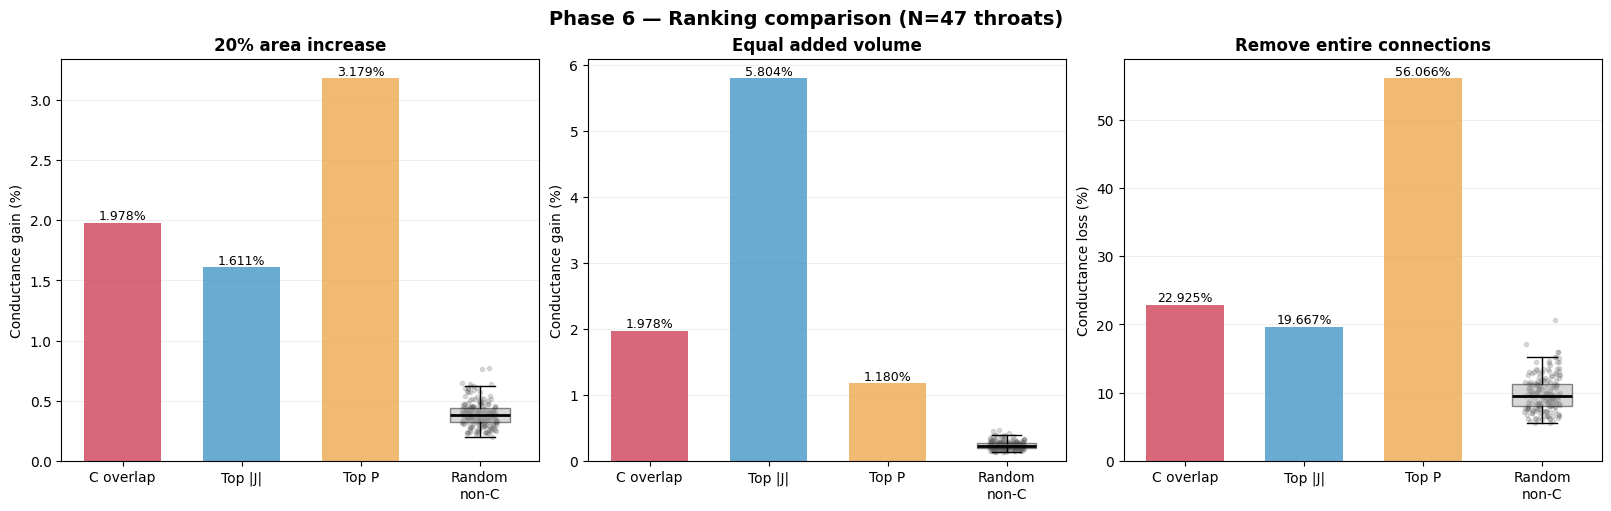

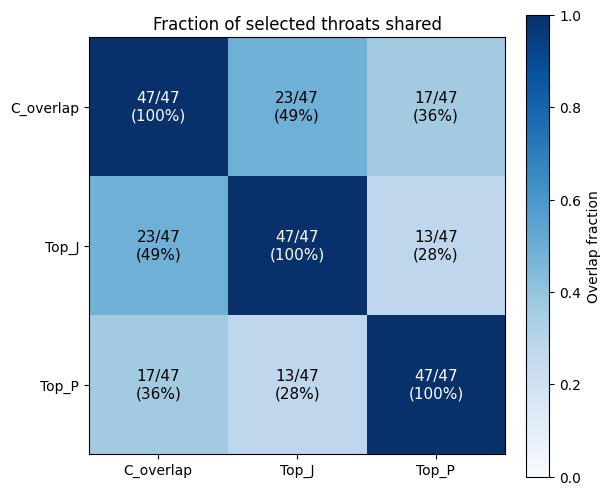

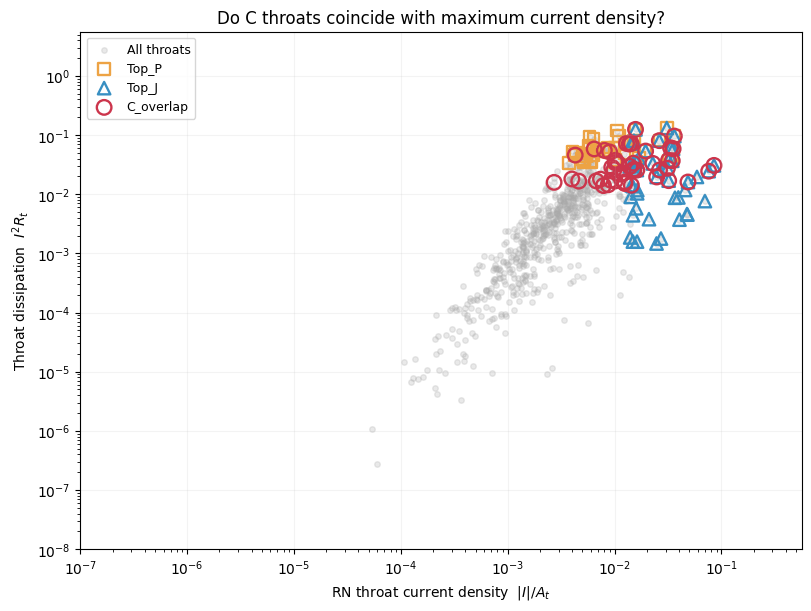


EQUAL-VOLUME CONDUCTANCE IMPROVEMENT


,group,effect_pct,area_increase,volume_added,gain_per_porosity_pp
1,C_overlap,1.97814,0.20000,3215.66619,20.76151
4,Top_J,5.80409,0.97143,3215.66619,60.91679
7,Top_P,1.18005,0.06896,3215.66619,12.38526


In [124]:
def phase6_plot_ranking_comparison(comparison):
    """Visualize C versus top-J, top-P and random selections."""
    import numpy as np
    import matplotlib.pyplot as plt
    from IPython.display import display

    results = comparison["results"]
    overlap = comparison["overlap"]
    ranks = comparison["ranks"]
    sets = comparison["sets"]
    N = comparison["N"]

    names = ["C_overlap", "Top_J", "Top_P"]

    colors = {
        "C_overlap": "#cc354c",
        "Top_J": "#388fc2",
        "Top_P": "#eda344",
        "Random_nonC": "#999999",
    }

    modes = [
        ("fixed_area", "20% area increase",
         "Conductance gain (%)"),
        ("equal_volume", "Equal added volume",
         "Conductance gain (%)"),
        ("block", "Remove entire connections",
         "Conductance loss (%)"),
    ]

    # ==========================================
    # 1. Intervention comparison
    # ==========================================

    fig1, axes = plt.subplots(
        1, 3,
        figsize=(16, 5),
        constrained_layout=True,
    )

    rng = np.random.default_rng(123)

    for ax, (mode, title, ylabel) in zip(
        axes, modes
    ):
        sub = results[
            results.intervention == mode
        ]

        for i, name in enumerate(names):
            d = sub[sub.group == name]

            if len(d) == 0:
                continue

            effect = float(d.effect_pct.iloc[0])

            ax.bar(
                i, effect,
                width=0.65,
                color=colors[name],
                alpha=0.75,
            )

            ax.text(
                i, effect,
                f"{effect:.3f}%",
                ha="center",
                va="bottom",
                fontsize=9,
            )

        # Random non-C distribution
        random = sub.loc[
            sub.group == "Random_nonC",
            "effect_pct",
        ].to_numpy(float)

        if len(random):
            ax.boxplot(
                [random],
                positions=[3],
                widths=0.5,
                patch_artist=True,
                showfliers=False,
                boxprops={
                    "facecolor": "#aaaaaa",
                    "alpha": 0.45,
                },
                medianprops={
                    "color": "black",
                    "linewidth": 2,
                },
            )

            ax.scatter(
                3 + rng.uniform(
                    -0.15, 0.15, len(random)
                ),
                random,
                s=9,
                alpha=0.22,
                color="#666666",
            )

        ax.set_xticks(
            range(4),
            ["C overlap", "Top |J|", "Top P", "Random\nnon-C"],
        )

        ax.set_title(title, weight="bold")
        ax.set_ylabel(ylabel)
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)

    fig1.suptitle(
        f"Phase 6 — Ranking comparison (N={N} throats)",
        fontsize=14,
        weight="bold",
    )

    plt.show()

    # ==========================================
    # 2. Selection overlap
    # ==========================================

    matrix = (
        overlap.pivot(
            index="set1",
            columns="set2",
            values="fraction_of_N",
        )
        .loc[names, names]
    )

    fig2, ax = plt.subplots(
        figsize=(6, 5),
        constrained_layout=True,
    )

    im = ax.imshow(
        matrix.to_numpy(),
        cmap="Blues",
        vmin=0,
        vmax=1,
    )

    ax.set_xticks(range(3), names)
    ax.set_yticks(range(3), names)

    for i in range(3):
        for j in range(3):
            fraction = matrix.iloc[i, j]
            count = round(fraction * N)

            ax.text(
                j, i,
                f"{count}/{N}\n({fraction:.0%})",
                ha="center",
                va="center",
                color="white" if fraction > 0.5 else "black",
                fontsize=11,
            )

    ax.set_title("Fraction of selected throats shared")
    fig2.colorbar(im, ax=ax, label="Overlap fraction")

    plt.show()

    # ==========================================
    # 3. Current density vs throat dissipation
    # ==========================================

    fig3, ax = plt.subplots(
        figsize=(8, 6),
        constrained_layout=True,
    )

    valid = ranks[
        ranks.eligible
        & (ranks.current_density > 0)
        & (ranks.throat_dissipation > 0)
    ]

    ax.scatter(
        valid.current_density,
        valid.throat_dissipation,
        color="#aaaaaa",
        s=16,
        alpha=0.25,
        label="All throats",
    )

    # Draw overlapping selections with hollow markers
    for name, marker, size in [
        ("Top_P", "s", 70),
        ("Top_J", "^", 80),
        ("C_overlap", "o", 110),
    ]:
        chosen = ranks.iloc[sets[name]]

        chosen = chosen[
            (chosen.current_density > 0)
            & (chosen.throat_dissipation > 0)
        ]

        ax.scatter(
            chosen.current_density,
            chosen.throat_dissipation,
            marker=marker,
            s=size,
            facecolors="none",
            edgecolors=colors[name],
            linewidths=1.7,
            label=name,
        )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel(r"RN throat current density  $|I|/A_t$")
    ax.set_ylabel(r"Throat dissipation  $I^2 R_t$")

    ax.set_title(
        "Do C throats coincide with maximum current density?"
    )
    ax.set_xlim(1e-7,None)
    ax.set_ylim(1e-8,None)
    ax.legend(loc="upper left", fontsize=9)
    ax.grid(alpha=0.15)


    plt.show()

    # ==========================================
    # 4. Print deterministic comparisons
    # ==========================================

    print("\nEQUAL-VOLUME CONDUCTANCE IMPROVEMENT")

    equal = results[
        (results.intervention == "equal_volume")
        & (results.group != "Random_nonC")
    ]

    display(
        equal[
            [
                "group",
                "effect_pct",
                "area_increase",
                "volume_added",
                "gain_per_porosity_pp",
            ]
        ].round(5)
    )

    return fig1, fig2, fig3


fig_rankings, fig_overlap, fig_J_vs_P = (
    phase6_plot_ranking_comparison(
        ranking_comparison
    )
)

0.5697116062647575